<h2 align = 'center'> Brazilian E-Commerce Public Dataset by Olist </h2>
<div align="center"> 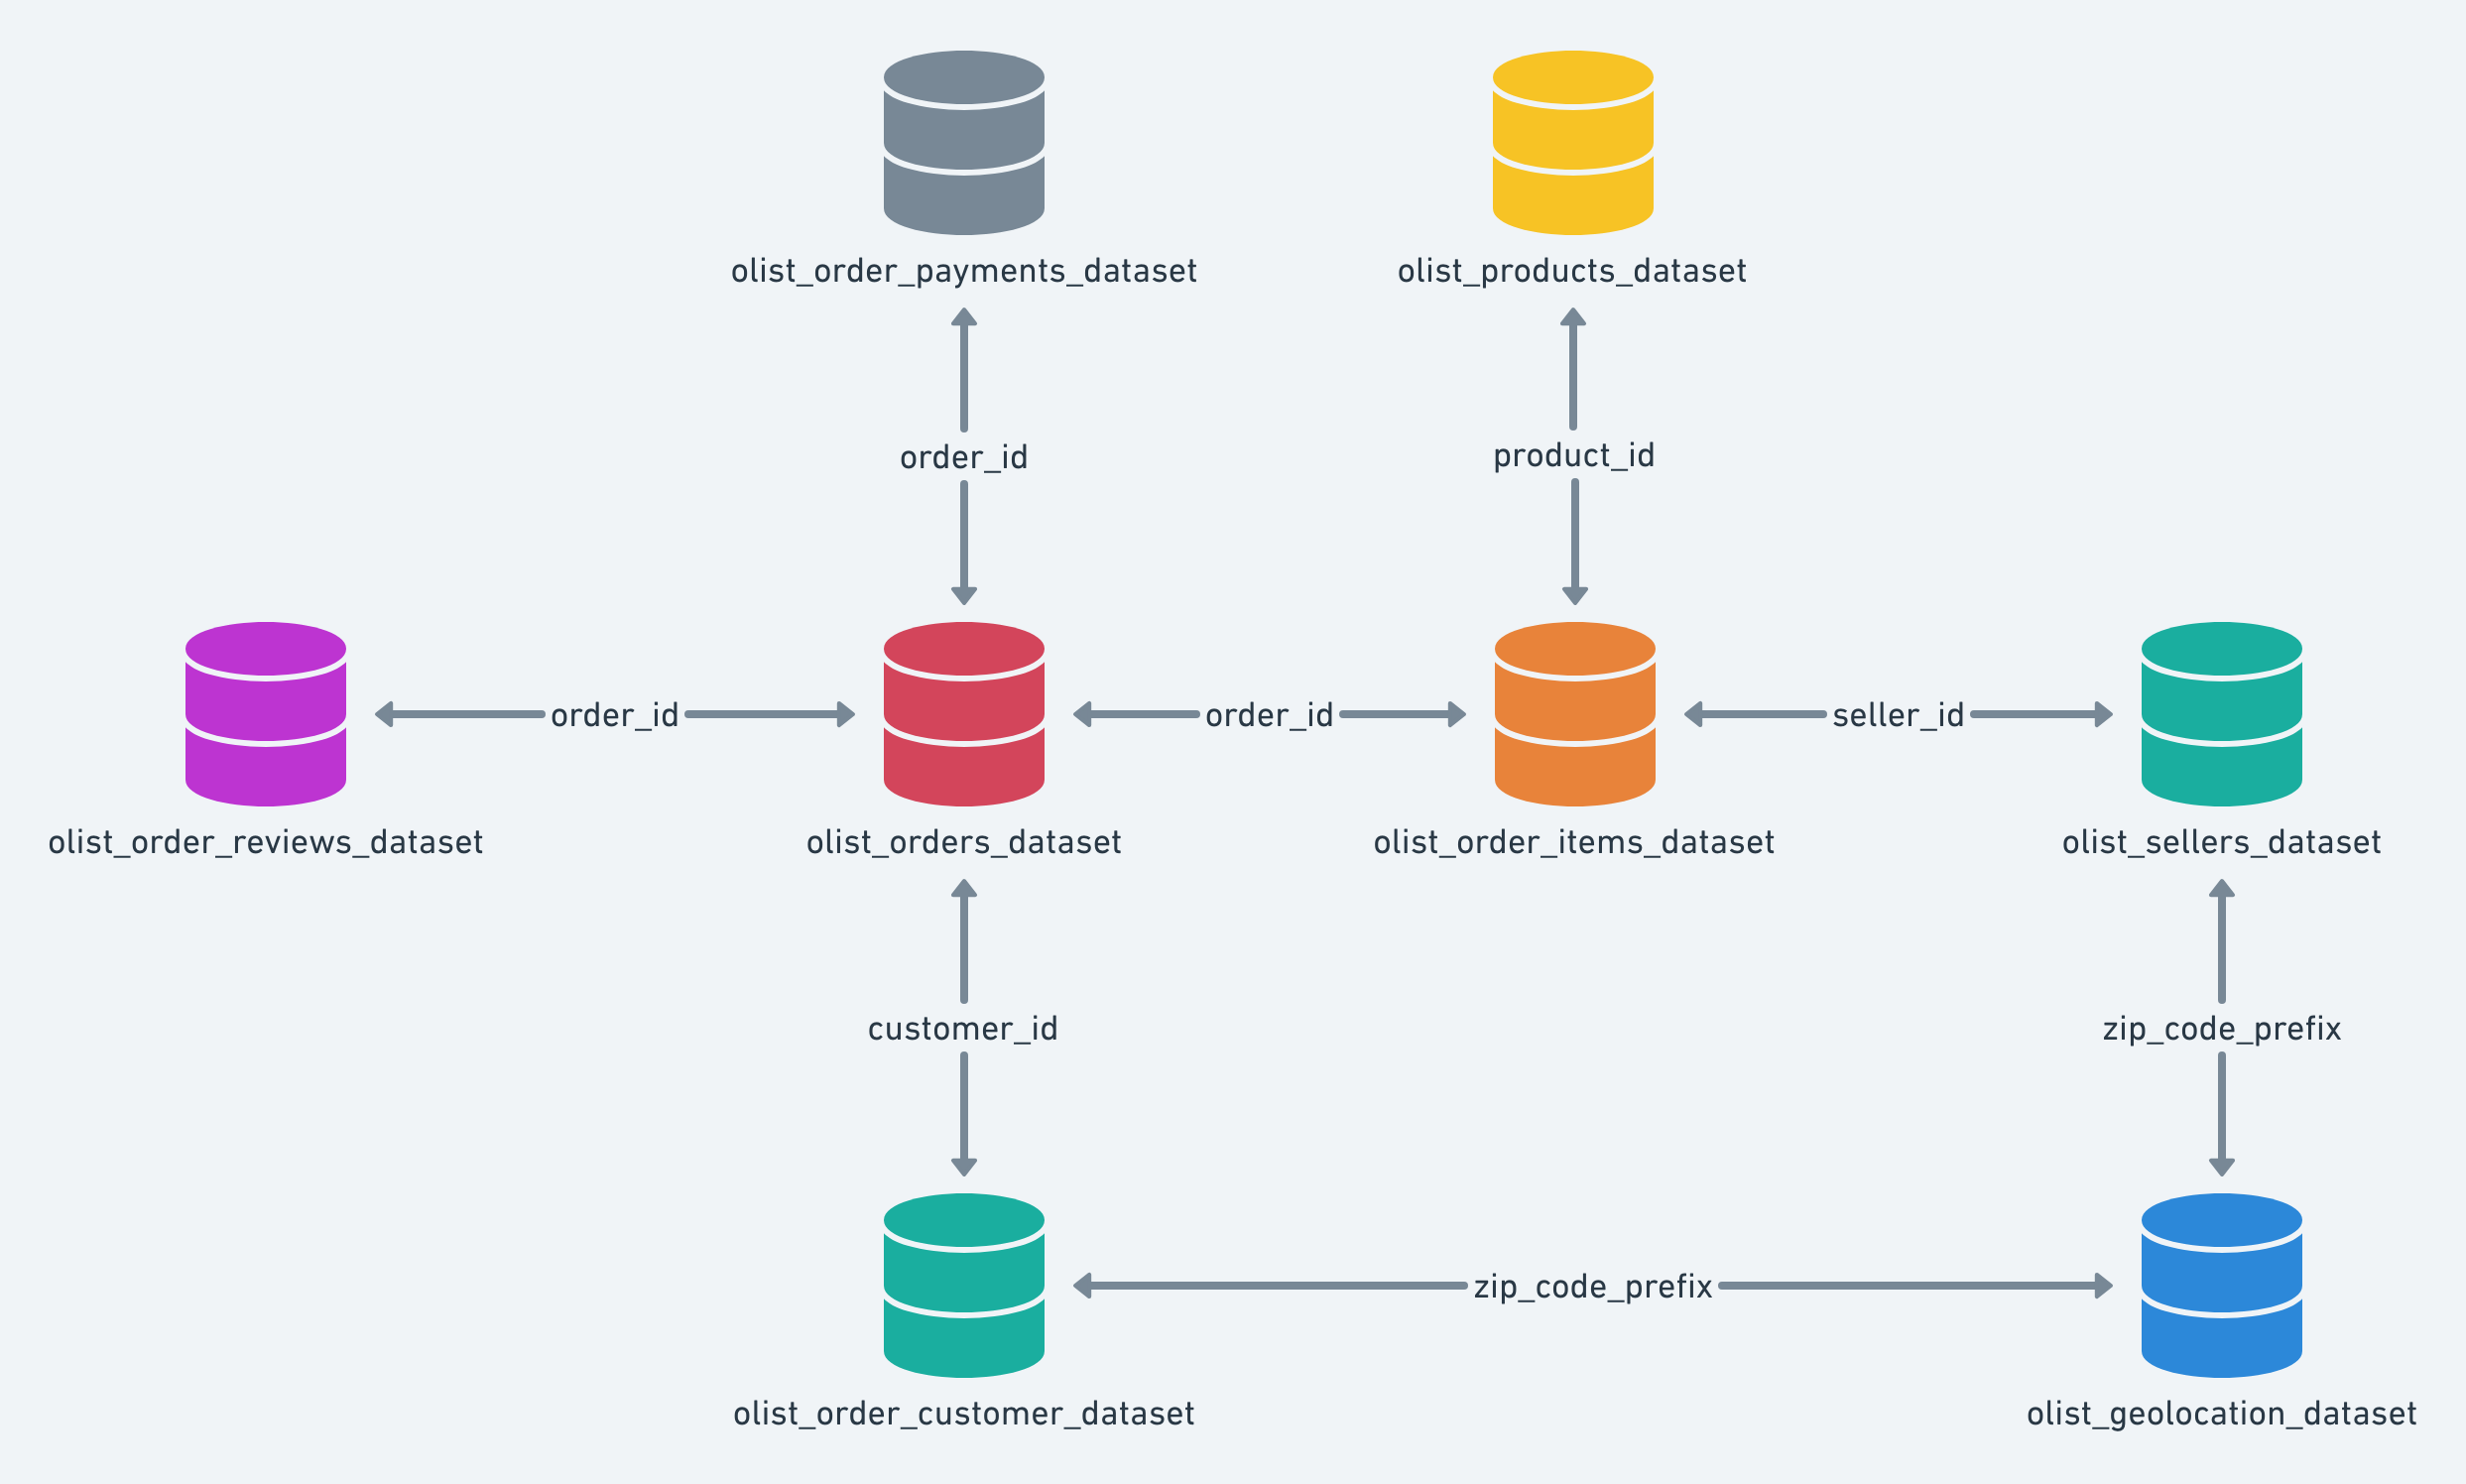 </div>


<div align="center"> <img src="https://storage.googleapis.com/kaggle-datasets-images/55151/105464/d59245a7014a35a35cc7f7b721de4dae/dataset-cover.png?t=2018-09-21-16-21-21" alt="Centered image"> </div>

Добро пожаловать! Это общедоступный бразильский набор данных о заказах, сделанных в интернет-магазине Olist. В наборе данных содержится информация о 100 000 заказов, сделанных с 2016 по 2018 год на различных торговых площадках Бразилии. С его помощью можно просмотреть заказ в разных аспектах: от статуса заказа, цены, оплаты и доставки до местоположения покупателя, характеристик товара и, наконец, отзывов покупателей. Мы также опубликовали набор данных с геолокацией, в котором бразильские почтовые индексы сопоставлены с координатами широты и долготы.

In [1]:
#Библиотеки для EDA
import joblib
import mlflow
import mlflow.sklearn
import mlflow.catboost
import mlflow.lightgbm
import duckdb
import pandas as pd
import numpy as np
import scipy.stats as st
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from cycler import cycler
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
import shap
#ML
import optuna
from imblearn.under_sampling import RandomUnderSampler

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)
from sklearn.model_selection import (
    train_test_split,
    cross_validate,
    KFold,
    RandomizedSearchCV,
    GridSearchCV
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import (
    LinearRegression,
    Ridge, 
    Lasso,
    ElasticNet
)
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

#Metrics
from sklearn.metrics import (
    mean_squared_error
)

Импортирование библиотек

In [2]:
warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)
TEST_SIZE = 0.25
RANDOM_STATE = 42
BURN_IN_MONTHS = 3
HORIZON_MONTHS = 6
cv=KFold(shuffle=True,n_splits=5,random_state=RANDOM_STATE)
p_value = 0.05

#colors
colormap = sns.diverging_palette(220, 10, as_cmap = True)
colorbox = [
    "#fb4934",  # Красный
    "#fabd2f",  # Желтый
    "#b8bb26",  # Зеленый
    "#83a598",  # Голубой
    "#d3869b",  # Фиолетовый
    "#fe8019",  # Ораньжевый
    "#8ec07c",  # Бирюзовый
]

rc = {
    "axes.facecolor": "#282828",
    "figure.facecolor": "#282828",
    "axes.edgecolor": "#3c3836",
    "grid.color": "#504945",
    "axes.labelcolor": "#ebdbb2",
    "xtick.color": "#d5c4a1",
    "ytick.color": "#d5c4a1",
    "grid.alpha": 0.3,
    "axes.prop_cycle": cycler(color=colorbox),
    "legend.facecolor": "#DCDCDC",
    "text.color": "ebdbb2", 
    "axes.titlecolor": "white",
    "xtick.color": "white",
    "ytick.color": "white",
    "legend.labelcolor": "white",
    "legend.title_fontsize": 12,
}

sns.set(rc=rc, style="darkgrid")
# Устанавливаем настройку rc и стиль "darkgrid" seaborn

Константы

In [126]:
#Функция для визуализации EDA графиков: гистограмма, boxplot
def num_plot(data,column_list,bins=50,figsize=(6,3)):
    for column in column_list:
        plt.figure(figsize=(figsize))
        # Первый subplot - ГИСТОГРАММА
        plt.subplot(1,2,1)
        sns.histplot(data=data,x=column,kde=True,bins=bins, palette=colorbox, alpha=0.7)
        plt.title(f'Гистограмма частоты {column}',color='white')
        plt.xlabel(f'Значения {column}',color='white')
        plt.ylabel('Частота',color='white')
        plt.grid()
        # Второй subplot - BOXPLOT
        plt.subplot(1,2,2)
        sns.boxplot(data=data,y=column, palette=colorbox)
        plt.title(f'Boxplot {column}',color='white')
        plt.xlabel('Boxplot',color='white')
        plt.ylabel('Значения',color='white')
        plt.grid()
        plt.show()

#Функция визуализации pie charm
def pie_charm(series,title='',colors=[colorbox[0],colorbox[1]]):
    vc_series = series.value_counts()
    values = vc_series.values
    index = list(vc_series.index)
    plt.figure(figsize=(14, 7))
    plt.pie(
        values,
        labels=index,
        startangle=90, frame=True, radius=1.3,
        wedgeprops={'linewidth': 1, 'edgecolor': 'white'},
        textprops={'fontsize': 12, 'weight': 'bold'},
        autopct='%1.1f%%',
        colors=colors,
    )
    plt.legend()
    plt.title(title,color='white')
    plt.show()

#Функция для визуализации EDA графиков: countplot
def count_plot(data,column_list,figsize=(9,3),palette=colorbox, rotation=90):
    for column in column_list:
        plt.figure(figsize=figsize)
        sns.countplot(data=data,x=column,palette=colorbox)
        plt.title(f'Количество {column}',color='white')
        plt.xlabel('Значения',color='white')
        plt.ylabel('Количество значений',color='white')
        plt.xticks(fontsize=7,rotation=rotation)
        plt.show()

#Функция визуализации линейной зависимости
def plotlm(data, x_var, y_var, row_var=None, target=None):
    plt.figure(figsize=(14,7))
    lm = sns.lmplot(
        data=data,
        x=x_var,
        y=y_var,
        row=row_var,
        hue = row_var,
        lowess=True,
        height=2,
        aspect=4,
        palette=palette_sex ,
        col=target,
        line_kws={"color": "white"},
        scatter_kws={"alpha": 0.3},
    )
    for ax in lm.axes.flatten():
        ax.tick_params(color='white')
        ax.xaxis.label.set_color("white")
        ax.yaxis.label.set_color("white")

        lm.set_titles(
            col_template="Target value:{col_name}",
            color="white",
            size=12,
            weight="bold"
    )
    plt.suptitle(
        f"{x_var.replace('_', ' ').title()} VS {y_var.replace('_', ' ').title()} by Target Variable",
        y=1.02,
        fontsize=16,color='white',
    )
    plt.tight_layout()
    plt.show()

#SMAPE
def smape(target, predict):
    target = np.asarray(target)
    predict = np.asarray(predict)
    denominator = (np.abs(target) + np.abs(predict)) / 2
    mask = denominator != 0
    return np.mean(
        np.abs(target[mask] - predict[mask]) / denominator[mask]
    )

Функции

# Загрузка данных и первичный анализ

In [4]:
olist_customers = pd.read_csv('datasets/olist/olist_customers_dataset.csv')
olist_geo = pd.read_csv('datasets/olist/olist_geolocation_dataset.csv')
olist_order_items = pd.read_csv('datasets/olist/olist_order_items_dataset.csv')
olist_order_payments = pd.read_csv('datasets/olist/olist_order_payments_dataset.csv')
olist_order_reviews = pd.read_csv('datasets/olist/olist_order_reviews_dataset.csv')
olist_orders = pd.read_csv('datasets/olist/olist_orders_dataset.csv')
olist_products = pd.read_csv('datasets/olist/olist_products_dataset.csv')
olist_sellers = pd.read_csv('datasets/olist/olist_sellers_dataset.csv')
product_cat_name_translation = pd.read_csv('datasets/olist/product_category_name_translation.csv')

#### olist_customers

* customer_id - идентификатор, используемый для связи с заказами. Каждому заказу присваивается уникальный customer_id.
* customer_unique_id - уникальный идентификатор клиента. Поскольку один и тот же покупатель получает новый customer_id для каждого нового заказа, это поле позволяет отслеживать повторные покупки. Без него каждый заказ выглядел бы как сделанный новым клиентом.
* customer_zip_code_prefix - первые пять цифр почтового индекса.
* customer_city - город проживания клиента.
* customer_state - штат проживания клиента.

In [5]:
olist_customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [6]:
olist_customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB


In [7]:
print(f"Наличие явных дубликатов в датасете 'olist_customers': {olist_customers.duplicated().sum()}")
print(f"Наличие неявных дубликатов в датасете 'olist_customers': {olist_customers[['customer_unique_id','customer_id']].duplicated().sum()}")

Наличие явных дубликатов в датасете 'olist_customers': 0
Наличие неявных дубликатов в датасете 'olist_customers': 0


Таблица olist_customers содержит информацию о клиентах. Пропуски и дубликаты отсутствуют, названия строк соответствуют их содержанию, типы данных определены корректно.

In [8]:
print('Количество городов клиентов',olist_customers['customer_city'].nunique())
print('Количество штатов клиентов',olist_customers['customer_state'].nunique())

Количество городов клиентов 4119
Количество штатов клиентов 27


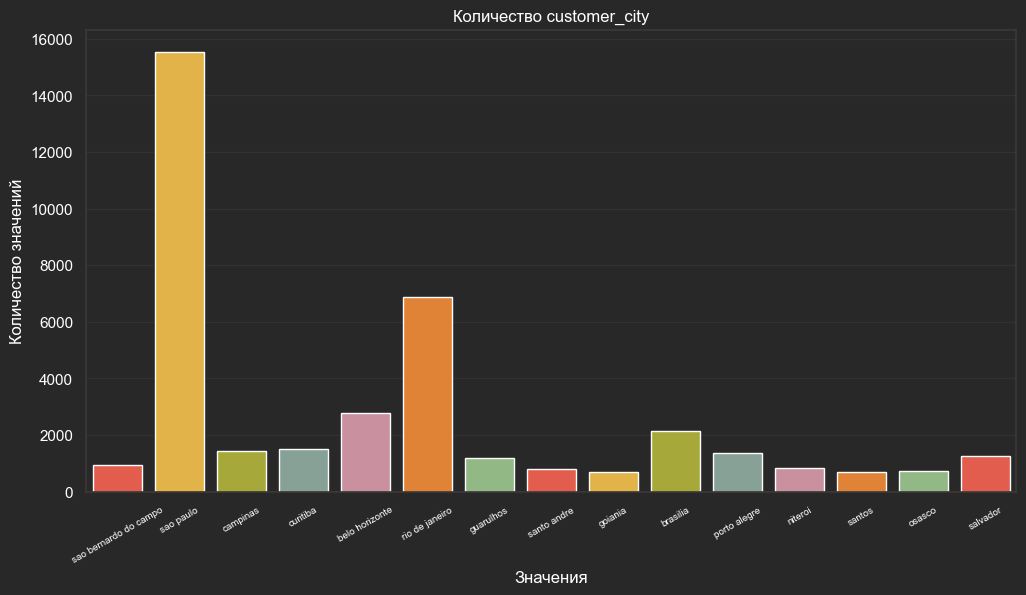

In [9]:
customer_city_names = olist_customers['customer_city'].value_counts().sort_values(ascending=False).index
customer_city_names = customer_city_names[:15]
the_most_frequent_cities = olist_customers.loc[olist_customers['customer_city'].isin(customer_city_names)]
count_plot(the_most_frequent_cities, ['customer_city'], figsize=(12,6), rotation=30)

Данные по городам показывают выраженную географическую концентрацию покупателей. Топ-15 городов возглавляет Сан-Паулу с большим отрывом - 15 540 заказов, что примерно в 2.3 раза больше, чем у следующего по популярности Рио-де-Жанейро (6 882). Остальные города уже существенно уступают: Белу-Оризонти (2 773), Бразилиа (2 131) и Куритиба (1 521)

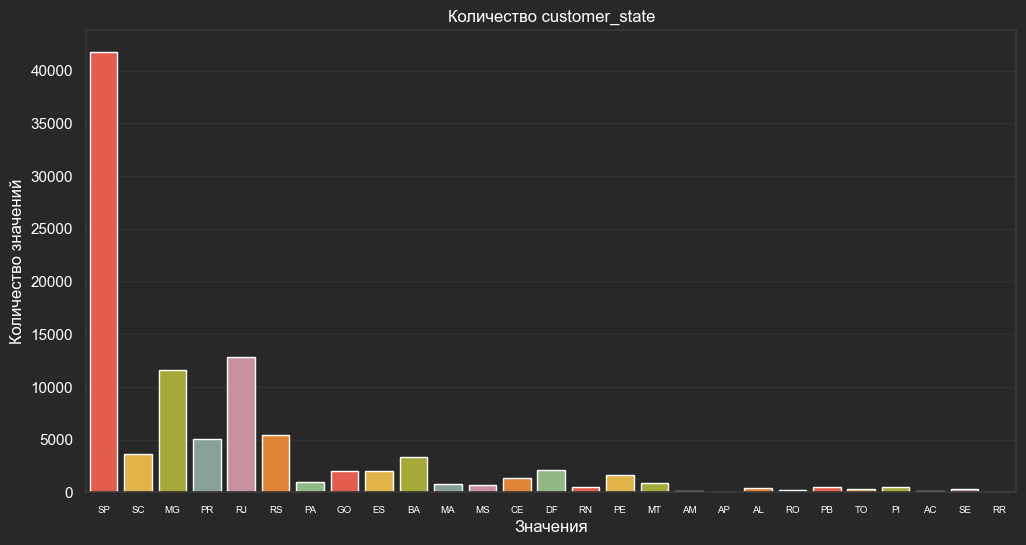

In [10]:
count_plot(olist_customers, ['customer_state'], figsize=(12,6), rotation=0)

На уровне штатов картина аналогичная: штат Сан-Паулу (SP) доминирует с 41 746 заказами - это почти треть всей выборки. За ним следуют Рио-де-Жанейро (RJ, 12 852) и Минас-Жерайс (MG, 11 635). Северные и северо-западные штаты (AM, AC, AP, RR) представлены крайне слабо (менее 200 заказов каждый), что отражает реальную экономическую диспропорцию регионов Бразилии. Для модели это означает потенциальный дисбаланс по географическому признаку, который стоит учесть при fe.

#### olist_geo

* geolocation_zip_code_prefix: первые 5 цифр почтового индекса.
* geolocation_lat: широта
* geolocation_lng: долгота
* geolocation_city: город
* geolocation_state штат

In [11]:
olist_geo.head()

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


In [12]:
olist_geo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city             1000163 non-null  object 
 4   geolocation_state            1000163 non-null  object 
dtypes: float64(2), int64(1), object(2)
memory usage: 38.2+ MB


#### olist_order_items

* order_id: уникальный идентификатор заказа.
* order_item_id: порядковый номер, определяющий количество товаров, включенных в один и тот же заказ.
* product_id: уникальный идентификатор продукта.
* seller_id: уникальный идентификатор продавца.
* shipping_limit_date: показывает дату отправки заказа продавцом логистическому партнеру.
* price: цена товара.
* freight_value: стоимость доставки товара

In [13]:
olist_order_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [14]:
olist_order_items.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB


In [15]:
print(f"Наличие явных дубликатов в датасете 'olist_order_items': {olist_order_items.duplicated().sum()}")
print(f"Наличие неявных дубликатов в датасете 'olist_order_items': {olist_order_items[['order_id','seller_id','product_id','order_item_id']].duplicated().sum()}")

Наличие явных дубликатов в датасете 'olist_order_items': 0
Наличие неявных дубликатов в датасете 'olist_order_items': 0


Таблица olist_order_items содержит информацию о предметах заказа. Пропуски и дубликаты отсутствуют, названия строк соответствуют их содержанию, типы данных определены корректно.

In [16]:
olist_order_items['shipping_limit_date'] = pd.to_datetime(
    olist_order_items['shipping_limit_date'],
    format='%Y-%m-%d %H:%M:%S'
)

Тип данных даты и времени был преобразован в верный

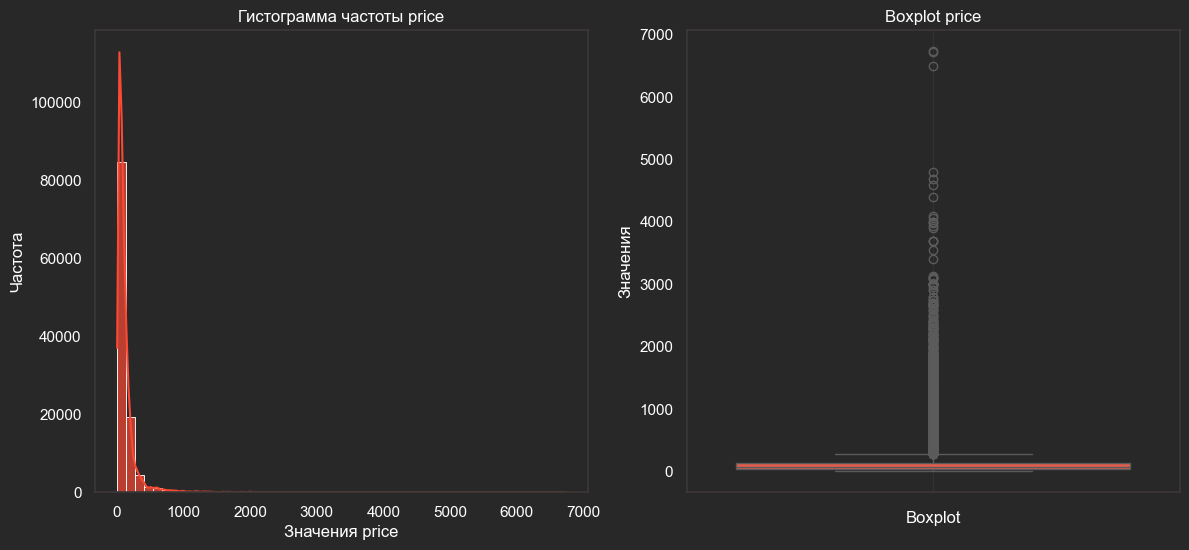

In [17]:
num_plot(olist_order_items,['price'], figsize=(14,6))

In [18]:
olist_order_items['price'].describe()


count    112650.000000
mean        120.653739
std         183.633928
min           0.850000
25%          39.900000
50%          74.990000
75%         134.900000
max        6735.000000
Name: price, dtype: float64

Распределение price сильно правосторонне скошено, дорогостоящие товары существенно смещают среднее. Основная масса заказов сосредоточена в диапазоне до 300 единиц, при этом медиана составляет всего 74.99, тогда как среднее - 120.65, что говорит о значительном влиянии выбросов на правом хвосте. Максимальное значение - 6 735, что в ~50 раз превышает медиану. IQR составляет 95 (от 39.90 до 134.90) - 50% заказов укладываются в относительно узкий диапазон недорогих товаров.
Стандартное отклонение 183.63 при среднем 120.65 говорит о крайне высокой дисперсии.

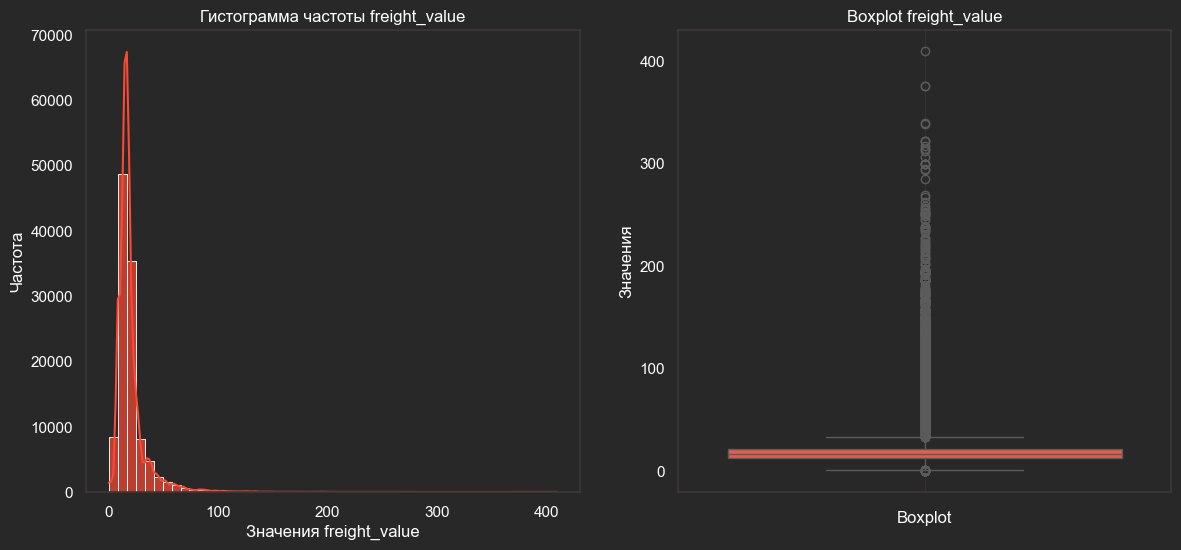

In [19]:
num_plot(olist_order_items,['freight_value'], figsize=(14,6))

In [20]:
olist_order_items['freight_value'].describe()


count    112650.000000
mean         19.990320
std          15.806405
min           0.000000
25%          13.080000
50%          16.260000
75%          21.150000
max         409.680000
Name: freight_value, dtype: float64

freight_value демонстрирует схожую картину правостороннего скоса, но менее экстремальную. Медиана равна 16.26, среднее - 19.99, IQR от 13.08 до 21.15. Максимум - 409.68, минимум - 0 (бесплатная доставка). Стандартное отклонение 15.81 умеренное относительно среднего, но выбросы присутствуют - боксплот показывает ряд значений в диапазоне от ~200 до ~410, которые, вероятно, соответствуют дорогостоящей доставке в отдалённые регионы

#### olist_order_payments

* order_id: уникальный идентификатор заказа.
* payment_sequential: клиент может оплатить заказ несколькими способами оплаты. Если он это сделает, будет создана последовательность.
* payment_type: способ оплаты, выбранный клиентом.
* payment_installments: количество платежей, выбранных клиентом.
* payment_value: стоимость транзакции.

In [21]:
olist_order_payments.head()


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [22]:
olist_order_payments.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  object 
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  object 
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), object(2)
memory usage: 4.0+ MB


In [23]:
print(f"Наличие явных дубликатов в датасете 'olist_order_payments': {olist_order_payments.duplicated().sum()}")

Наличие явных дубликатов в датасете 'olist_order_payments': 0


Таблица olist_order_payments содержит информацию о оплате заказов. Пропуски и дубликаты отсутствуют, названия строк соответствуют их содержанию, типы данных определены корректно.

In [24]:
print(f'Уникальные значения признака "payment_sequential":{olist_order_payments.payment_sequential.unique()}')

Уникальные значения признака "payment_sequential":[ 1  2  4  5  3  8  6  7 10 11 17 19 27 12  9 15 13 14 16 25 22 26 29 28
 18 21 24 23 20]


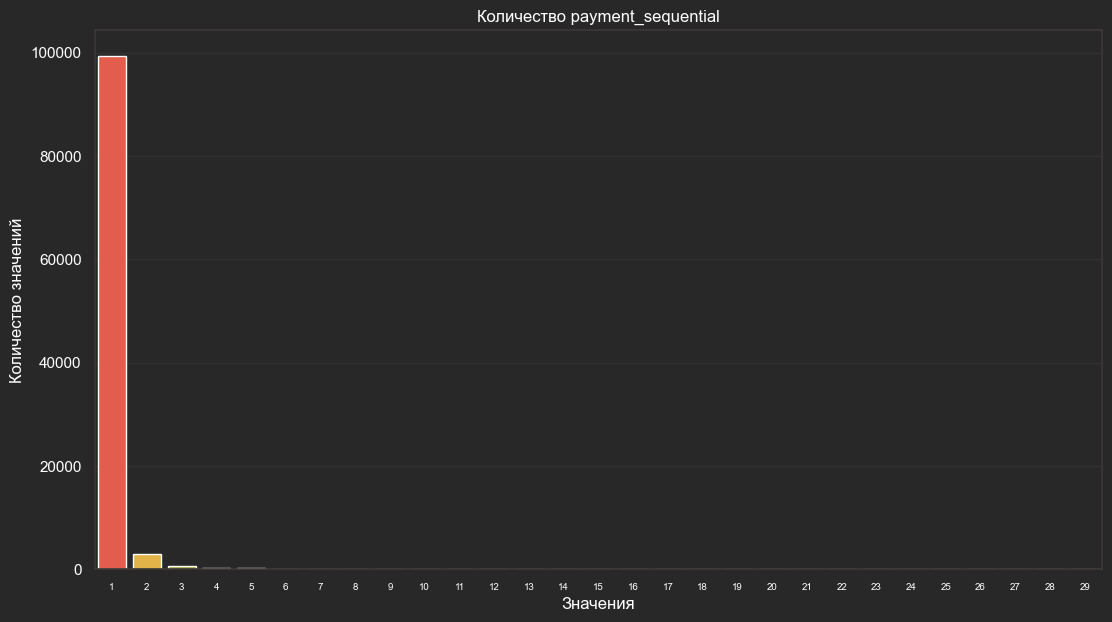

In [25]:
count_plot(olist_order_payments, ['payment_sequential'], figsize=(13,7), rotation=0)

Подавляющее большинство заказов оплачивается за один платёж - 99 360 из ~103 400, то есть около 96%. Два платежа используются уже в 3 039 случаях, а далее частота резко падает. Значения от 10 и выше единичны и могут представлять рассрочку на длительный срок. Признак сильно несбалансирован и в большинстве случаев будет нести мало информации. Возможно стоит трансформировать его в бинарный 1 платёж / более 1 платежа

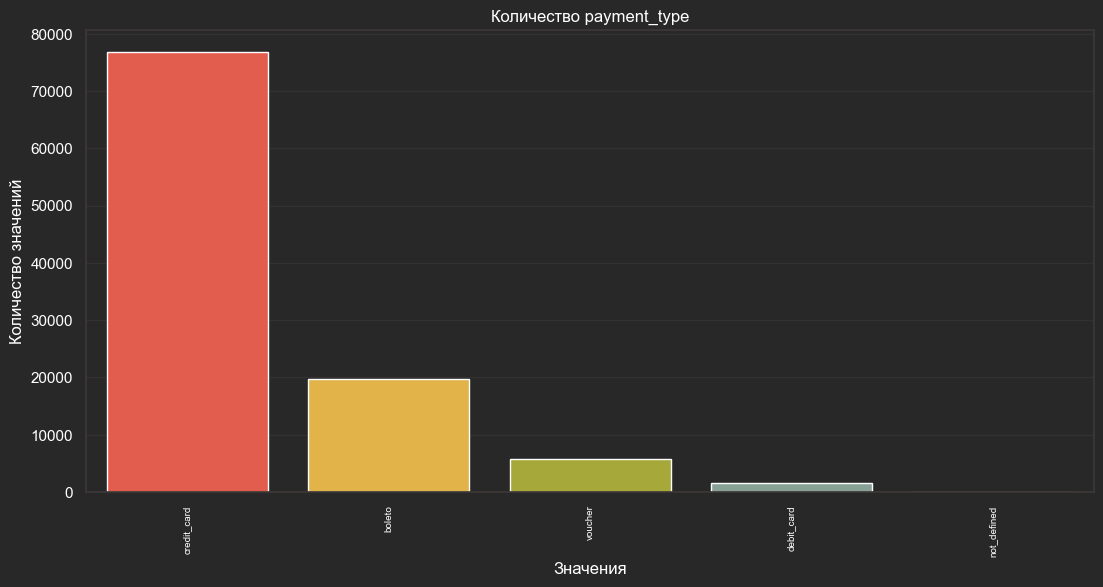

In [26]:
count_plot(olist_order_payments,['payment_type'],figsize=(13,6))

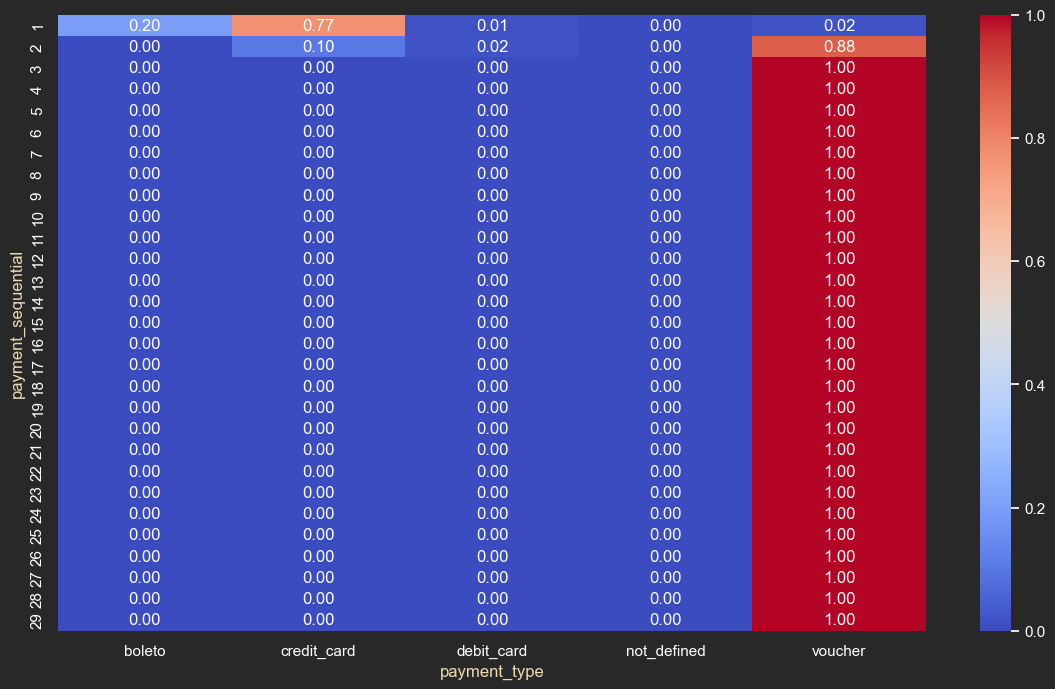

In [27]:
plt.figure(figsize=(14,8))
sns.heatmap(
    pd.crosstab(olist_order_payments['payment_sequential'], olist_order_payments['payment_type'], normalize='index'),
    annot = True,
    cmap = 'coolwarm',
    cbar = True,
    fmt = '.2f'
)
plt.grid()
plt.show()

Тепловая карта соотношения payment_sequential и payment_type выявляет чёткую закономерность: при одном платеже используются все типы оплаты (boleto - 20%, credit_card - 77%, debit_card - 1%, voucher - 2%). Начиная со второго платежа и далее используется только voucher (0.88 и выше, с третьего по двадцать девятый - 1.00)

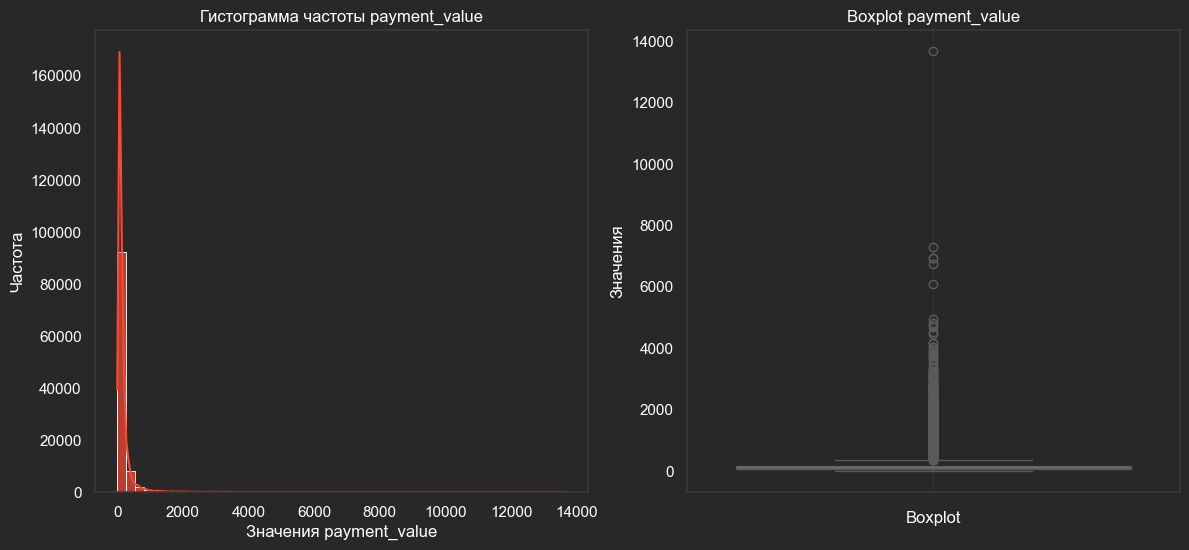

In [28]:
num_plot(olist_order_payments,['payment_value'],figsize=(14,6))

In [29]:
olist_order_payments['payment_value'].describe()

count    103886.000000
mean        154.100380
std         217.494064
min           0.000000
25%          56.790000
50%         100.000000
75%         171.837500
max       13664.080000
Name: payment_value, dtype: float64

#### olist_order_reviews

* review_id: уникальный идентификатор отзыва.
* order_id: уникальный идентификатор заказа.
* review_score: оценка заказа.
* review_comment_title: заголовок комментария.
* review_comment_message: комментарий к отзыву.
* review_creation_date: дата отзыва.
* review_answer_timestamp: дата ответа на отзыв.

In [30]:
olist_order_reviews.head()


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [31]:
olist_order_reviews.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                99224 non-null  object
 1   order_id                 99224 non-null  object
 2   review_score             99224 non-null  int64 
 3   review_comment_title     11568 non-null  object
 4   review_comment_message   40977 non-null  object
 5   review_creation_date     99224 non-null  object
 6   review_answer_timestamp  99224 non-null  object
dtypes: int64(1), object(6)
memory usage: 5.3+ MB


In [32]:
print(f"Наличие явных дубликатов в датасете 'olist_order_reviews': {olist_order_reviews.duplicated().sum()}")
print(f"Наличие неявных дубликатов в датасете 'olist_order_reviews': {olist_order_reviews[['review_id','order_id']].duplicated().sum()}")

Наличие явных дубликатов в датасете 'olist_order_reviews': 0
Наличие неявных дубликатов в датасете 'olist_order_reviews': 0


Таблица olist_order_reviews содержит информацию о отзывах на заказы. В данных содержатся пропуски в признаках текста отзывов, а также в заголовках отзывов. Можно предположить, что люди решили не писать комментарий к отзыву, а лишь оставить оценку заказу. Эта информация не подлежит восстановлению истинных значений, отсутствует более 50% значений, поэтому я решил заполнить пропуски костантным значением, чтобы не терять оценки заказов.

In [33]:
olist_order_reviews.fillna('NaN',inplace=True)

olist_order_reviews['review_creation_date'] = pd.to_datetime(
    olist_order_reviews['review_creation_date']
)
olist_order_reviews['review_answer_timestamp'] = pd.to_datetime(
    olist_order_reviews['review_answer_timestamp']
)

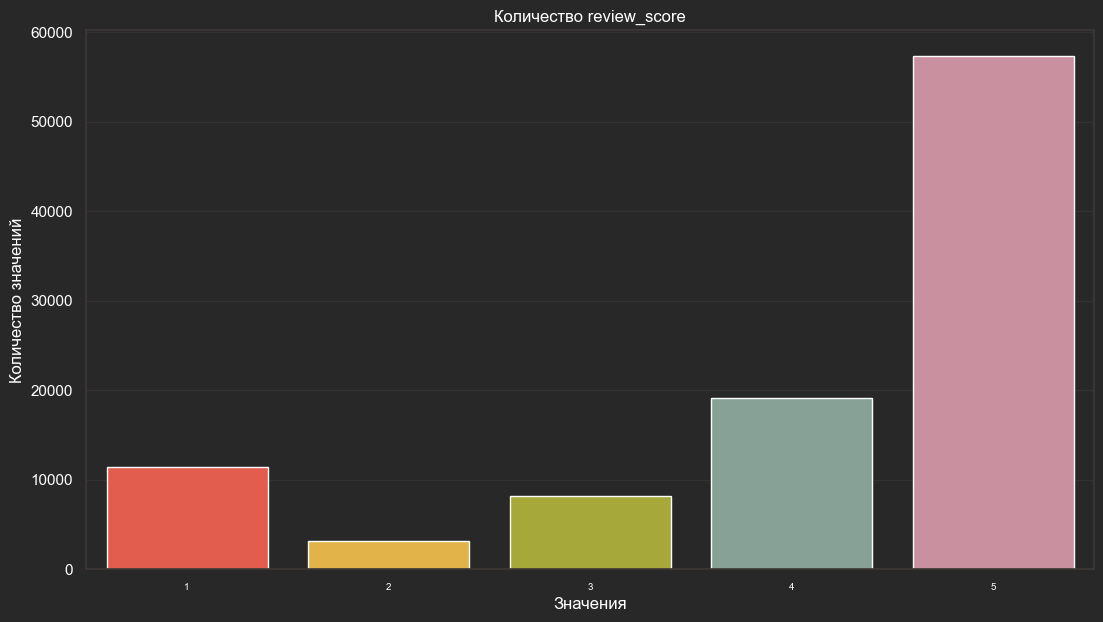

In [34]:
count_plot(olist_order_reviews,['review_score'], figsize=(13,7), rotation=0)

Распределение оценок явно несбалансированное и скошено в сторону положительных. Оценка 5 встречается чаще всего - 57 328 раз (~57% выборки). Оценка 4 - 19 142. При этом оценка 1 (11 424) занимает третье место и встречается заметно чаще, чем 3 (8 179) и 2 (3 151). Можно предположить, что люди зачастую ставят оценки только когда они очень довольны покупкой или когда разочарованы.

#### olist_orders

* order_id: уникальный идентификатор заказа.
* customer_id: ключ к набору данных о клиентах.
* order_status: ссылка на статус заказа.
* order_purchase_timestamp: показывает отметку времени покупки.
* order_approved_at: показывает отметку времени утверждения платежа.
* order_delivered_carrier_date: показывает отметку времени отправки заказа.
* order_delivered_customer_date: показывает фактическую дату доставки заказа клиенту.
* order_estimated_delivery_date: показывает предполагаемую дату доставки.

In [35]:
olist_orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [36]:
olist_orders.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [37]:
print(f"Наличие явных дубликатов в датасете 'olist_orders': {olist_orders.duplicated().sum()}")
print(f"Наличие неявных дубликатов в датасете 'olist_orders': {olist_orders[['customer_id','order_id']].duplicated().sum()}")

Наличие явных дубликатов в датасете 'olist_orders': 0
Наличие неявных дубликатов в датасете 'olist_orders': 0


Таблица olist_orders содержит информацию о заказе. Есть наличие пропусков и неверно определенных типов данных. Содержание пропусков локализируется в признаках с датами (3% даных), которые не подлежат восстановлению, эти строки можно удалить.

In [38]:
olist_orders.dropna(subset=[
    'order_approved_at',                    
    'order_delivered_carrier_date',                    
    'order_delivered_customer_date'
    ],inplace=True
)

In [39]:
olist_orders.isna().sum()

order_id                         0
customer_id                      0
order_status                     0
order_purchase_timestamp         0
order_approved_at                0
order_delivered_carrier_date     0
order_delivered_customer_date    0
order_estimated_delivery_date    0
dtype: int64

In [40]:
olist_orders['order_purchase_timestamp'] = pd.to_datetime(
    olist_orders['order_purchase_timestamp'],
    format='%Y-%m-%d %H:%M:%S'
)
olist_orders['order_approved_at'] = pd.to_datetime(
    olist_orders['order_approved_at'],
    format='%Y-%m-%d %H:%M:%S'
)
olist_orders['order_delivered_carrier_date'] = pd.to_datetime(
    olist_orders['order_delivered_carrier_date'],
    format='%Y-%m-%d %H:%M:%S'
)

olist_orders['order_estimated_delivery_date'] = pd.to_datetime(
    olist_orders['order_estimated_delivery_date'],
    format='%Y-%m-%d %H:%M:%S'
)

olist_orders['order_delivered_customer_date'] = pd.to_datetime(
    olist_orders['order_delivered_customer_date'],
    format='%Y-%m-%d %H:%M:%S'
)

Признаки даты и времени были приведены к единому типу datetime

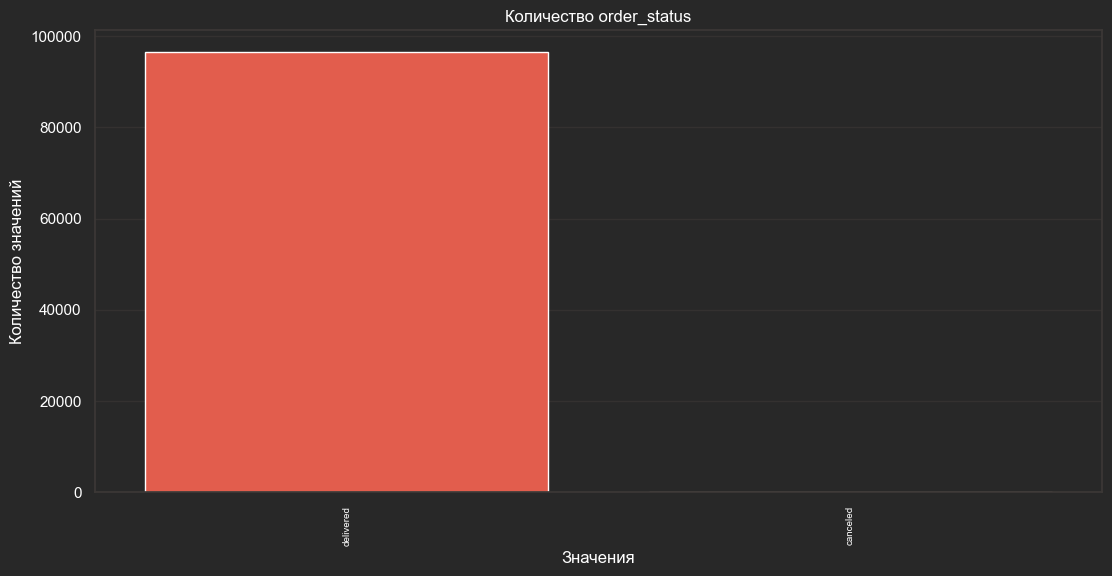

In [41]:
count_plot(olist_orders,['order_status'],figsize=(13,6))

In [42]:
olist_orders['order_status'].value_counts()

order_status
delivered    96455
canceled         6
Name: count, dtype: int64

Большинство заказов были доставлены (96455) и лишь 6 заказов были отменены.

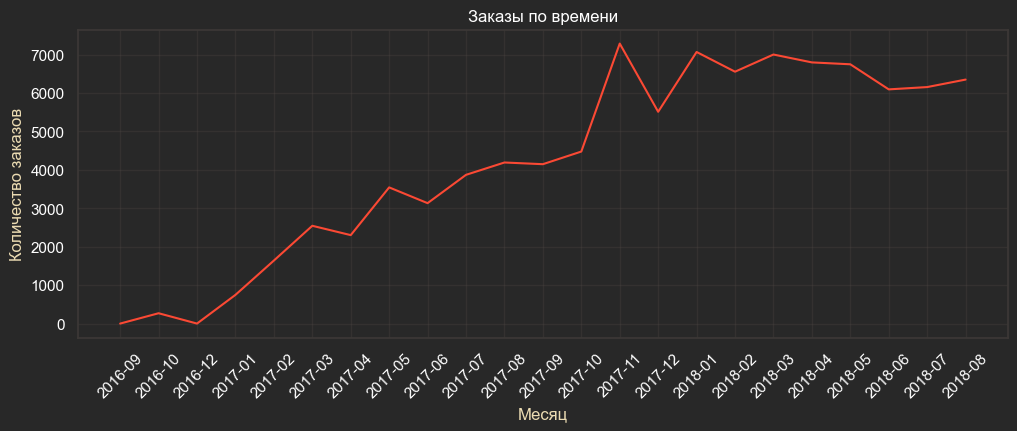

In [43]:
monthly_counts_orders = olist_orders['order_purchase_timestamp'].dt.to_period('M').value_counts().sort_index()

plt.figure(figsize=(12,4))
sns.lineplot(
    x=monthly_counts_orders.index.astype(str),
    y=monthly_counts_orders.values,
)
plt.xticks(rotation=45)
plt.xlabel('Месяц')
plt.ylabel('Количество заказов')
plt.title('Заказы по времени')
plt.show()

Наибольшее количество отзывов приходится на период с 2017-11 по 2018-08 (от 5500 до ~ 7000 отзывов в месяц). С 2016-10 по 2017-01 было минимальное количество отзывов (<200 в месяц). Вероятно, 2018 год вышел пиком продаж, а в 2016 бизнес только развивался. 2017-11 - месяцем с наибольшим объемом заказов (~ 7300)

#### olist_products

* product_id: уникальный идентификатор продукта.
* product_category_head: категория продукта.
* product_name_length: количество символов из названия продукта.
* product_description_length: количество символов из описания продукта.
* product_photos_qty: количество фотографий продукта.
* product_weight_g: вес продукта в граммах.
* product_length_cm: длина изделия ив сантиметрах.
* product height_cm: высота изделия в саинтиметрах.
* product_width_cm: ширина изделия в сантиметрах.

In [44]:
olist_products.head()


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [45]:
olist_products.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  object 
 1   product_category_name       32341 non-null  object 
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), object(2)
memory usage: 2.3+ MB


In [46]:
print(f"Наличие явных дубликатов в датасете 'olist_products': {olist_products.duplicated().sum()}")

Наличие явных дубликатов в датасете 'olist_products': 0


In [47]:
olist_products.isna().sum()

product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

Количество пропусков немного относительно выборки, можно удалить их при этом не потеряв много важной информации.

In [48]:
olist_products.dropna(inplace=True)

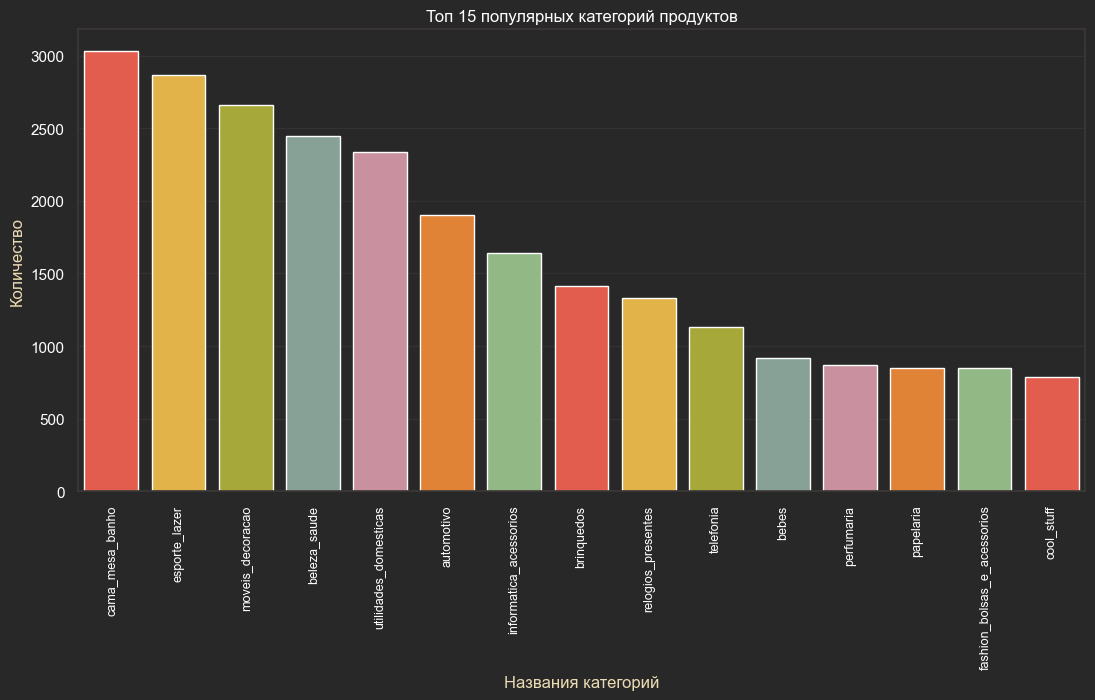

In [49]:
plt.figure(figsize=(13,6))
sns.barplot(olist_products['product_category_name'].value_counts().sort_values(ascending=False).head(15), palette=colorbox)
plt.title('Топ 15 популярных категорий продуктов')
plt.ylabel('Количество')
plt.xlabel('Названия категорий')
plt.xticks(fontsize=9, rotation=90)
plt.show()

In [50]:
print('Топ 10 популярных категорий товаров: \n \n', olist_products['product_category_name'].value_counts()[:10])

Топ 10 популярных категорий товаров: 
 
 product_category_name
cama_mesa_banho           3029
esporte_lazer             2867
moveis_decoracao          2657
beleza_saude              2444
utilidades_domesticas     2335
automotivo                1900
informatica_acessorios    1639
brinquedos                1411
relogios_presentes        1329
telefonia                 1134
Name: count, dtype: int64


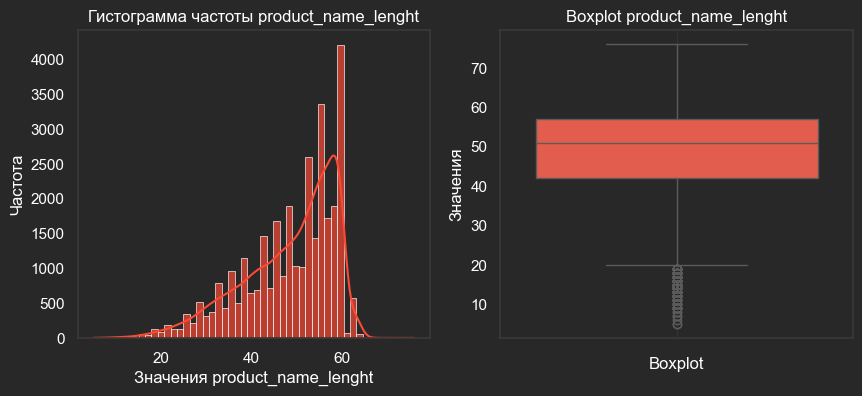

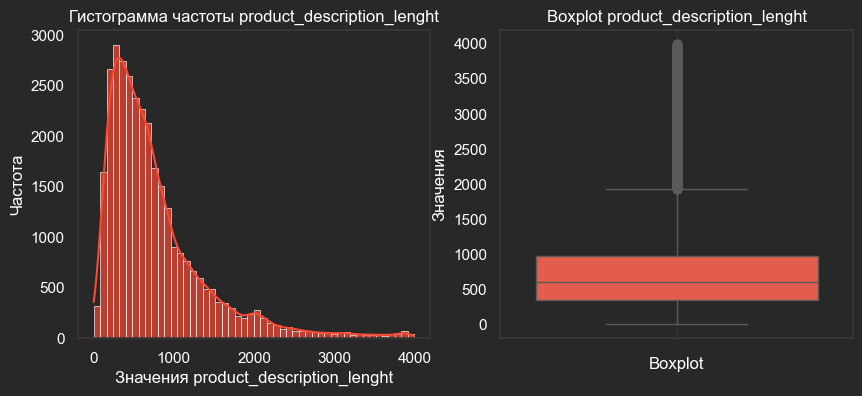

In [51]:
num_plot(olist_products, ['product_name_lenght', 'product_description_lenght'], figsize=(10,4))

In [52]:
print(olist_products['product_name_lenght'].describe(), '\n')
olist_products['product_name_lenght'].describe()

count    32340.000000
mean        48.476592
std         10.245699
min          5.000000
25%         42.000000
50%         51.000000
75%         57.000000
max         76.000000
Name: product_name_lenght, dtype: float64 



count    32340.000000
mean        48.476592
std         10.245699
min          5.000000
25%         42.000000
50%         51.000000
75%         57.000000
max         76.000000
Name: product_name_lenght, dtype: float64

**product_name_lenght и product_description_lenght**


* product_name_lenght: 

Распределение близко к нормальному - гистограмма симметрична с пиком около 55-60 символов, медиана (51) и среднее (48.5) близки, std умеренное (10.25). IQR от 42 до 57 - разброс небольшой. Боксплот показывает редкие выбросы снизу (минимум 5 символов). Признак не требует трансформаций перед масштабированием.

* product_description_lenght: 

Выраженный правый скос: пик гистограммы в диапазоне 200-500 символов, но среднее (771) заметно выше медианы (595) из-за длинного хвоста. IQR широкий - от 339 до 972. Максимум почти 4 000 символов.

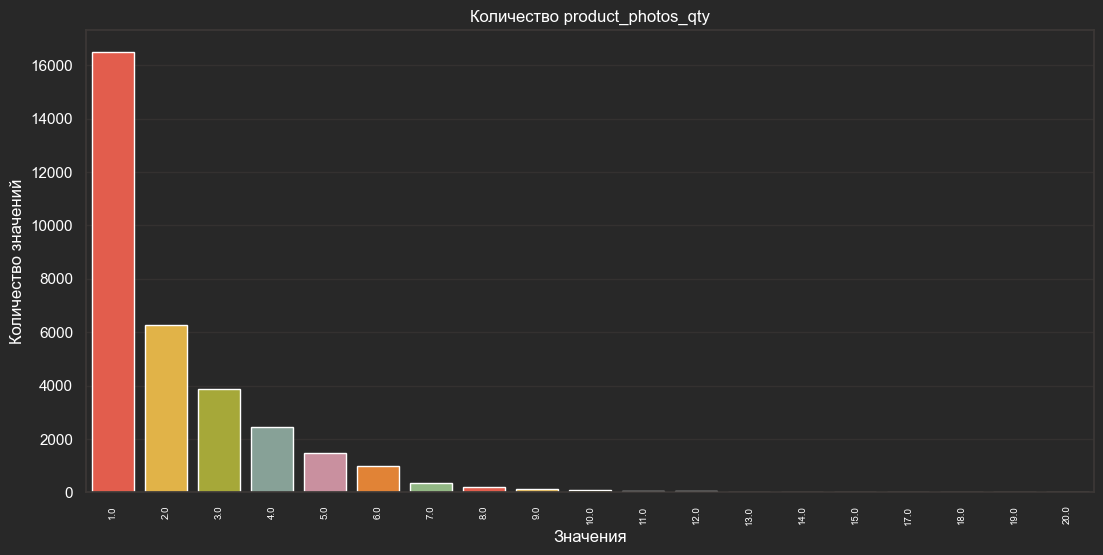

In [53]:
count_plot(olist_products, ['product_photos_qty'], figsize=(13,6))

Большинство продавцов прикладывают минимальное количество фото от 1 до 6. Больше 10 фотографий и до 20 встречаются очень редко

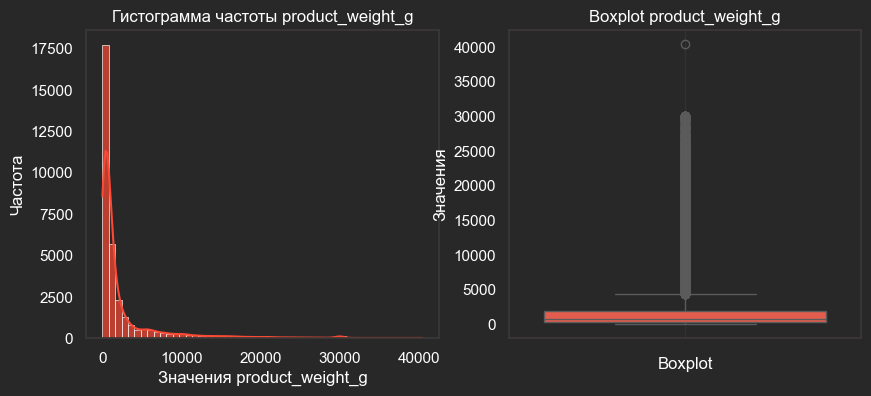

In [54]:
num_plot(olist_products, ['product_weight_g'], figsize=(10,4))

In [55]:
olist_products['product_weight_g'].describe()

count    32340.000000
mean      2276.956586
std       4279.291845
min          0.000000
25%        300.000000
50%        700.000000
75%       1900.000000
max      40425.000000
Name: product_weight_g, dtype: float64

Вес товара - один из самых скошенных признаков в датасете. Медиана - 700 г, среднее - 2 276 г, максимум - 40 425 г. Стандартное отклонение (4 282) почти вдвое превышает среднее (дисперсия экстремальная). IQR от 300 до 1 900 г показывает, что 50% товаров.

In [56]:
olist_products.loc[olist_products['product_weight_g'] > 40000]

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
25166,26644690fde745fc4654719c3904e1db,cama_mesa_banho,59.0,534.0,1.0,40425.0,13.0,65.0,28.0


В признаке product_weight_g зафиксирована аномальная запись: товар категории cama_mesa_banho имеет вес 40 425 г при габаритах 13×65×28 см. Такое соотношение веса и размеров физически нереалистично

In [57]:
olist_products = olist_products.loc[olist_products['product_weight_g'] < 40000]

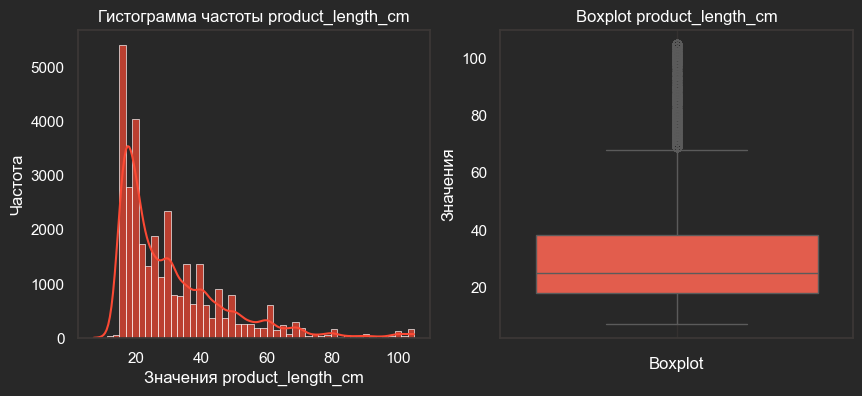

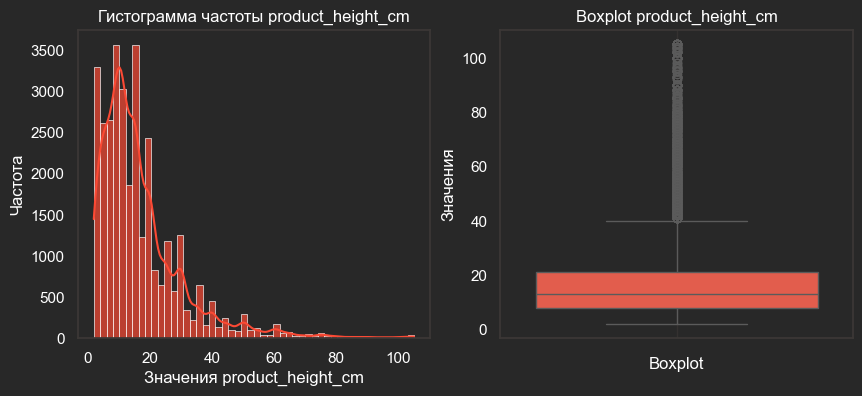

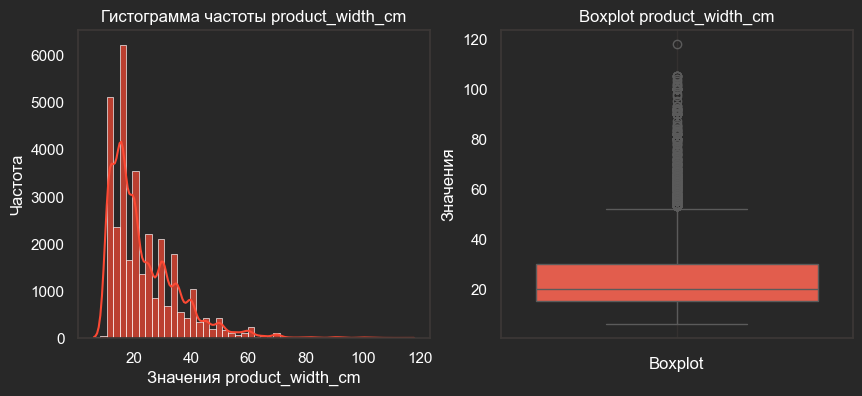

In [58]:
num_plot(olist_products, ['product_length_cm', 'product_height_cm', 'product_width_cm'], figsize=(10,4))

**product_length_cm, product_height_cm, product_width_cm**

Все три размерных признака демонстрируют схожую структуру - правосторонний скос с основной массой значений в нижнем диапазоне и длинным хвостом.

#### olist_sellers

* seller_id - уникальный идентификатор продавца.
* seller_zip_code_prefix - первые пять цифр почтового индекса.
* seller_city - город продавца.
* seller_state - штат продавца.

In [59]:
olist_sellers.head()


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


In [60]:
olist_sellers.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   seller_id               3095 non-null   object
 1   seller_zip_code_prefix  3095 non-null   int64 
 2   seller_city             3095 non-null   object
 3   seller_state            3095 non-null   object
dtypes: int64(1), object(3)
memory usage: 96.8+ KB


In [61]:
print(f"Наличие явных дубликатов в датасете 'olist_sellers': {olist_sellers.duplicated().sum()}")

Наличие явных дубликатов в датасете 'olist_sellers': 0


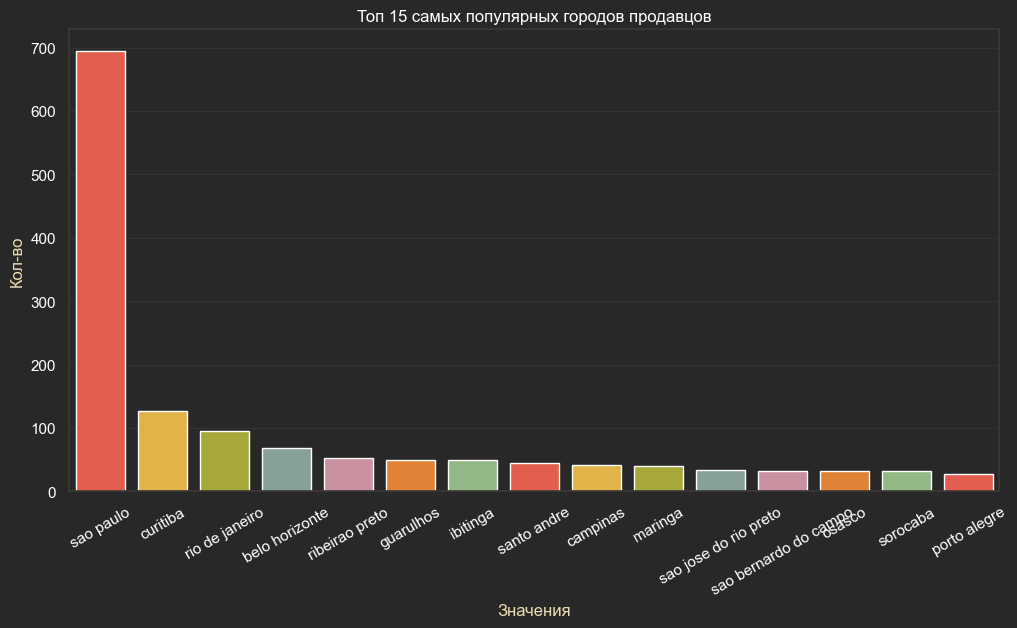

In [62]:
seller_city_names = olist_sellers['seller_city'].value_counts().sort_values(ascending=False).index
seller_city_names = seller_city_names[:15]
the_most_frequent_seller_cities = olist_sellers.loc[olist_sellers['seller_city'].isin(seller_city_names)]

plt.figure(figsize=(12,6))
sns.barplot(data=the_most_frequent_seller_cities['seller_city'].value_counts(), palette=colorbox)
plt.title("Топ 15 самых популярных городов продавцов")
plt.ylabel("Кол-во")
plt.xlabel("Значения")
plt.xticks(rotation=30)
plt.show()

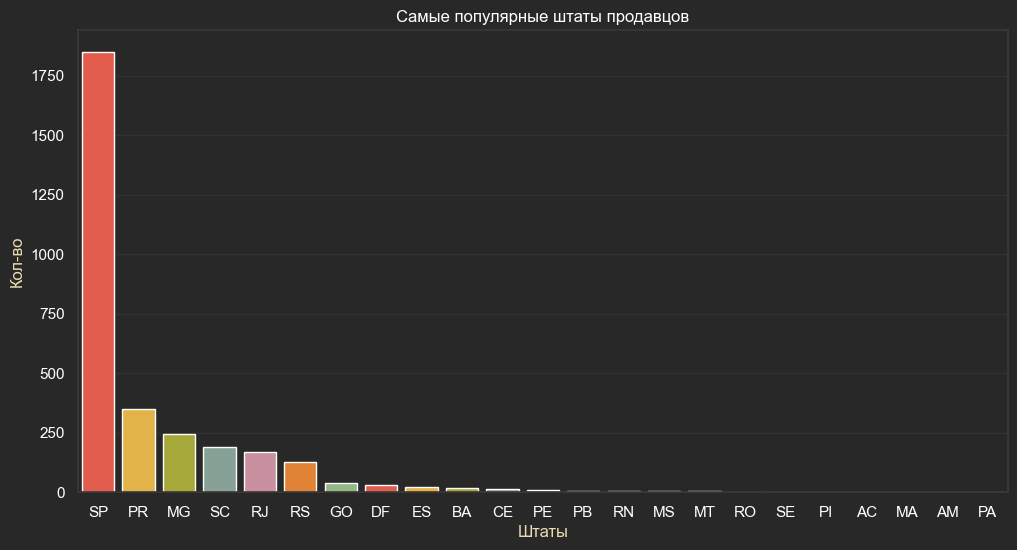

In [63]:
plt.figure(figsize=(12,6))
sns.barplot(data=olist_sellers['seller_state'].value_counts(), palette=colorbox)
plt.title("Cамые популярные штаты продавцов")
plt.ylabel("Кол-во")
plt.xlabel("Штаты")
plt.show()

Продавцы сконцентрированы ещё сильнее, чем покупатели. Штат Сан-Паулу (SP) даёт 1 849 продавцов из ~3 095 (почти 60%). Следующие: Парана (PR, 349) и Минас-Жерайс (MG, 244). Многие штаты представлены единицами продавцов (AC, MA, AM, PA по 1). Среди городов лидирует Сан-Паулу (694), далее Куритиба (127) и Рио-де-Жанейро (96).

#### product_cat_name_translation

* product_category_name - название на родном языке
* product_category_name_english - перевод на английский

In [64]:
product_cat_name_translation.head()


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


In [65]:
product_cat_name_translation.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 71 entries, 0 to 70
Data columns (total 2 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   product_category_name          71 non-null     object
 1   product_category_name_english  71 non-null     object
dtypes: object(2)
memory usage: 1.2+ KB


In [66]:
print(f"Наличие явных дубликатов в датасете 'product_cat_name_translation': {product_cat_name_translation.duplicated().sum()}")

Наличие явных дубликатов в датасете 'product_cat_name_translation': 0


# Join таблиц

In [67]:
df = olist_orders.merge(
    olist_customers[['customer_id', 'customer_state']],
    on='customer_id', how='left'
).merge(
    olist_order_items[['order_id', 'price', 'freight_value']],
    on='order_id', how='left'
)
df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_state,price,freight_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,SP,29.99,8.72
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,BA,118.70,22.76
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,GO,159.90,19.22
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,RN,45.00,27.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,SP,19.90,8.72


In [68]:
df = df[df['order_status'] == 'delivered'].copy()
df = df.set_index('order_purchase_timestamp')

monthly = (
    df.groupby('customer_state')
    .resample('MS')
    .agg(
        num_orders    = ('order_id','nunique'),
        total_revenue = ('price','sum'),
        avg_price     = ('price','mean'),
        total_freight = ('freight_value','sum')
    )
    .reset_index()
    .sort_values(['customer_state', 'order_purchase_timestamp'])
    .reset_index(drop=True)
)

print('Размерность bare датасета:', monthly.shape)
monthly.head(10)

Размерность bare датасета: (601, 6)


,customer_state,order_purchase_timestamp,num_orders,total_revenue,avg_price,total_freight
0,AC,2017-01-01,2,589.60,147.400000,133.54
1,AC,2017-02-01,3,450.40,75.066667,147.00
2,AC,2017-03-01,2,455.99,227.995000,74.19
3,AC,2017-04-01,5,1162.38,232.476000,189.13
4,AC,2017-05-01,8,2094.39,261.798750,277.34
5,AC,2017-06-01,4,385.78,96.445000,124.49
6,AC,2017-07-01,5,618.69,123.738000,175.71
7,AC,2017-08-01,4,637.93,159.482500,127.90
8,AC,2017-09-01,5,1786.89,357.378000,242.34
9,AC,2017-10-01,5,683.22,136.644000,180.58


In [69]:
monthly.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 601 entries, 0 to 600
Data columns (total 6 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   customer_state            601 non-null    object        
 1   order_purchase_timestamp  601 non-null    datetime64[ns]
 2   num_orders                601 non-null    int64         
 3   total_revenue             601 non-null    float64       
 4   avg_price                 556 non-null    float64       
 5   total_freight             601 non-null    float64       
dtypes: datetime64[ns](1), float64(3), int64(1), object(1)
memory usage: 28.3+ KB


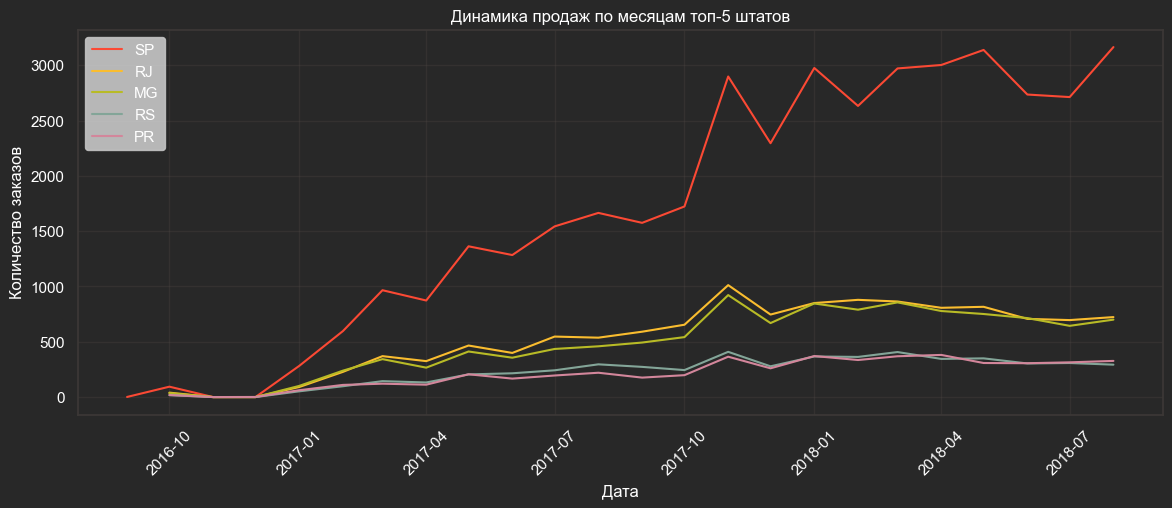

In [70]:
top5_states = (
    monthly.groupby('customer_state')['num_orders']
    .sum().sort_values(ascending=False).head(5).index.tolist()
)

plt.figure(figsize=(14, 5))
for state in top5_states:
    state_data = monthly[monthly['customer_state'] == state]
    sns.lineplot(
        data=state_data,
        x='order_purchase_timestamp',
        y='num_orders',
        label=state
    )
plt.title('Динамика продаж по месяцам топ-5 штатов', color='white')
plt.xlabel('Дата', color='white')
plt.ylabel('Количество заказов', color='white')
plt.xticks(rotation=45)
plt.legend()
plt.show()

Все пять штатов демонстрируют выраженный восходящий тренд с сентября 2016 по август 2018. SP доминирует с большим отрывом и к середине 2018 года достигает ~ 3 000-3 200 заказов в месяц, что в 4 раза превышает ближайших конкурентов RJ и MG (~ 700-900). Заметный скачок у всех штатов наблюдается в октябре-ноябре 2017, вероятно, сезонный эффект (Чёрная пятница, предновогодние покупки). После январского спада 2018 продажи стабилизируются на высоком уровне. RS и PR пользуются меньшей популярностью(~ 300-500).

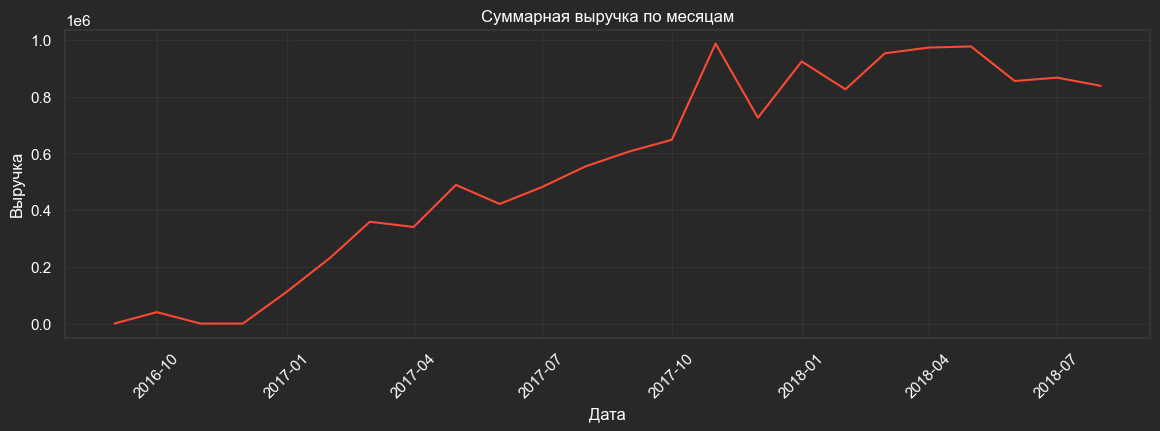

In [71]:
revenue_monthly = monthly.groupby('order_purchase_timestamp').agg(
    sum_revenue_by_month = ('total_revenue','sum'),
    num_orders_by_month = ('num_orders','sum')
).reset_index()

revenue_monthly['revenue_and_num_orders_ratio'] = revenue_monthly['sum_revenue_by_month'] / revenue_monthly['num_orders_by_month']

plt.figure(figsize=(14, 4))
sns.lineplot(data=revenue_monthly, x='order_purchase_timestamp', y='sum_revenue_by_month', color=colorbox[0])
plt.title('Суммарная выручка по месяцам', color='white')
plt.xlabel('Дата', color='white')
plt.ylabel('Выручка', color='white')
plt.xticks(rotation=45)
plt.show()

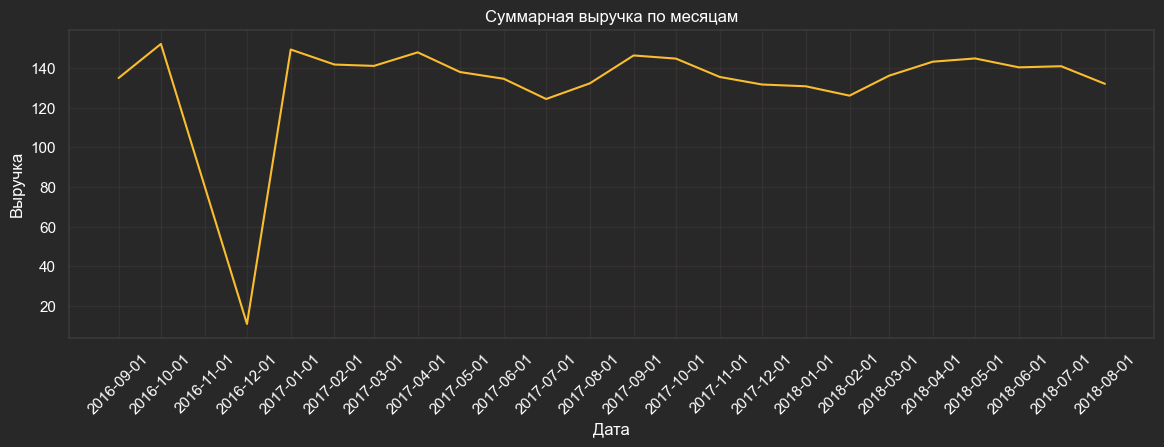

In [72]:
plt.figure(figsize=(14, 4))
sns.lineplot(data=revenue_monthly, x='order_purchase_timestamp', y='revenue_and_num_orders_ratio', color=colorbox[1])
plt.title('Суммарная выручка по месяцам', color='white')
plt.xlabel('Дата', color='white')
plt.ylabel('Выручка', color='white')
plt.xticks(
    revenue_monthly['order_purchase_timestamp'],
    rotation=45
)
plt.show()

Выручка увеличивается практически синхронно с количеством заказов, тогда как средняя стоимость заказа остается стабильной (~ 140). Это говорит о том, что рост дохода обеспечивается увеличением объема продаж, а не изменением среднего чека. Начало датасета (сентябрь–декабрь 2016) содержит неполные данные и не является репрезентативным для анализа.

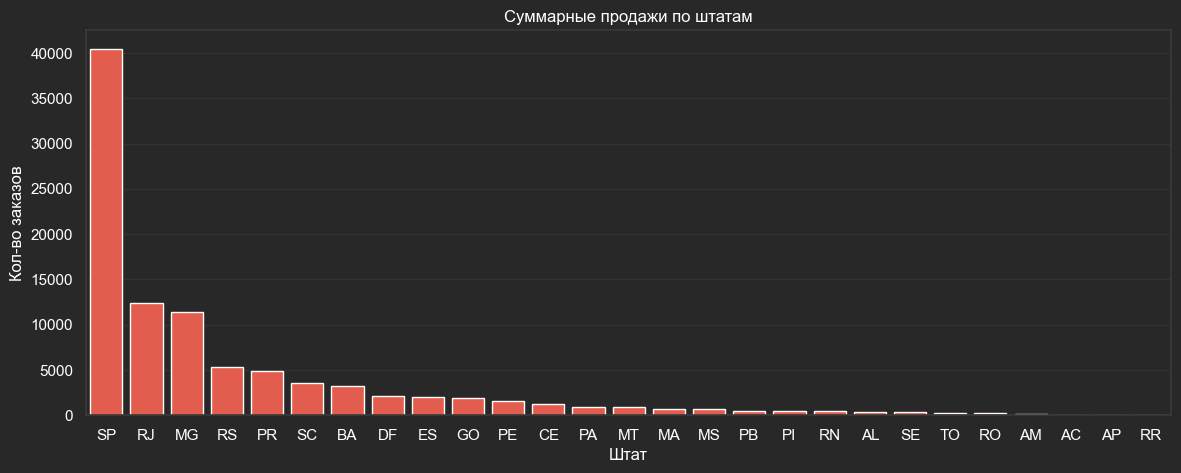

In [73]:
state_total = monthly.groupby('customer_state')['num_orders'].sum().sort_values(ascending=False).reset_index()
plt.figure(figsize=(14, 5))
sns.barplot(data=state_total, x='customer_state', y='num_orders', color=colorbox[0])
plt.title('Суммарные продажи по штатам', color='white')
plt.xlabel('Штат', color='white')
plt.ylabel('Кол-во заказов', color='white')
plt.show()


Географическая концентрация продаж крайне высокая. SP формирует 40 488 заказов - это ~ 41% всей выборки. Тройка лидеров SP+RJ+MG суммарно даёт ~ 65% всех продаж. RR, AP, AC, AM представлены единицами - менее 150 заказов за весь период. Такой дисбаланс означает что модель будет обучаться преимущественно на паттернах крупных штатов,а для малых штатов точность прогноза будет ниже из-за нехватки данных

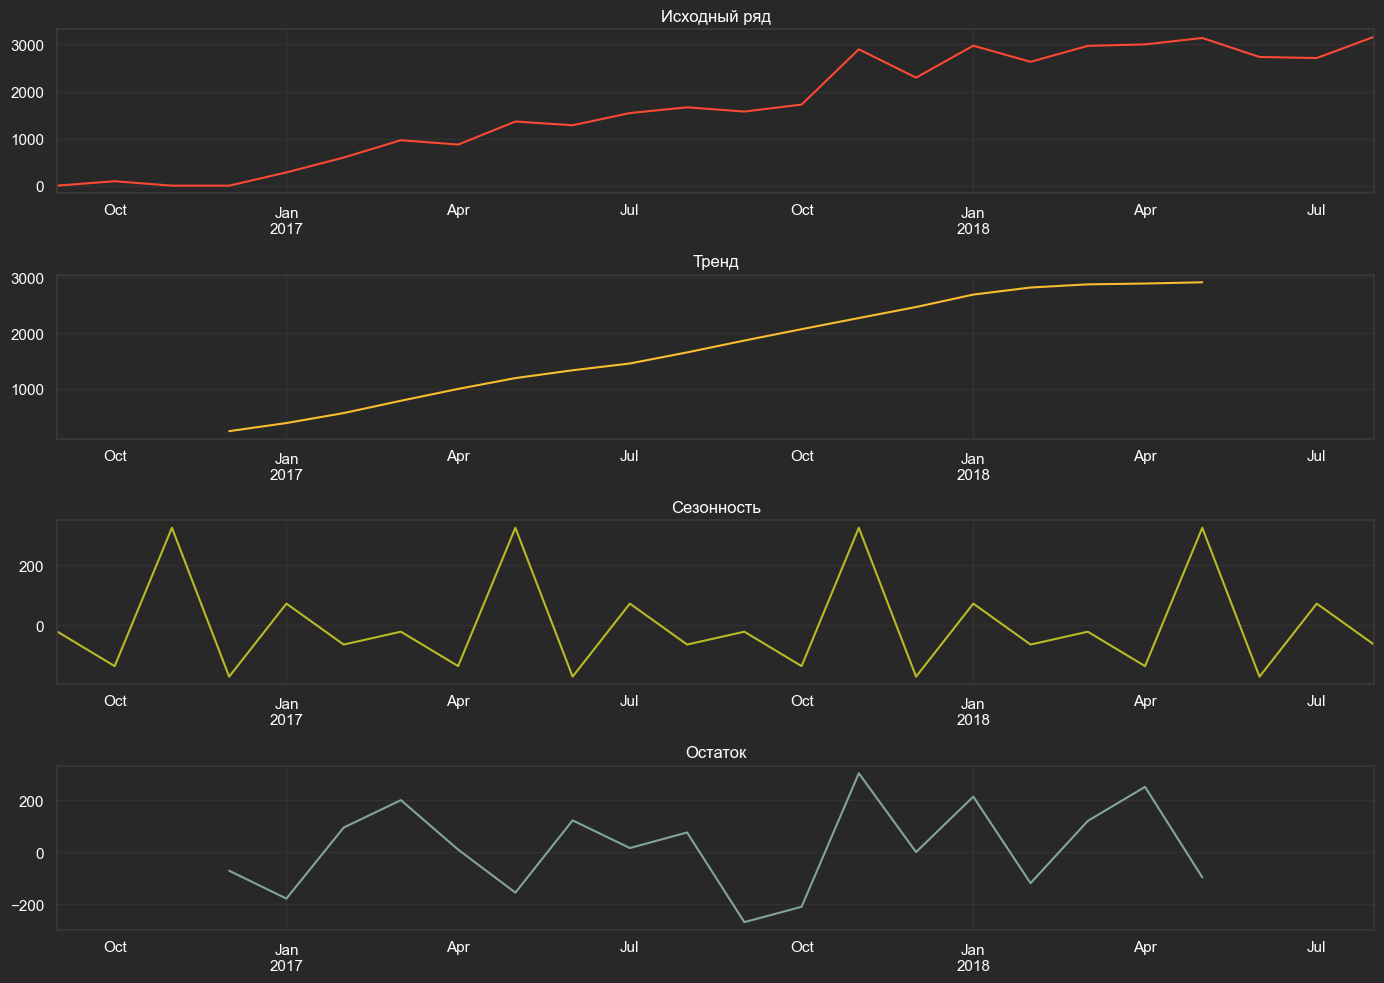

In [74]:
sp = monthly[monthly['customer_state'] == 'SP'].set_index('order_purchase_timestamp')
decomp = seasonal_decompose(sp['num_orders'], model='additive', period=6)

fig, axes = plt.subplots(4, 1, figsize=(14, 10))
sp['num_orders'].plot(ax=axes[0], title='Исходный ряд', color=colorbox[0])
decomp.trend.plot(ax=axes[1], title='Тренд', color=colorbox[1])
decomp.seasonal.plot(ax=axes[2], title='Сезонность', color=colorbox[2])
decomp.resid.plot(ax=axes[3], title='Остаток', color=colorbox[3])
for ax in axes:
    ax.set_xlabel('')
    
plt.tight_layout()
plt.show()

Тренд: сильный плавный рост продаж. Бизнес активно рос с сентября 2016 по январь 2018, потом плато.

Сезонность: есть, амплитуда ~ 200 заказов, пики повторяются каждые 6 месяцев, пики одинаковые по высоте, аддитивная модель выбрана правильно.

Остаток: крупные выбросы в Октябре 2017, а также в Январе и в Апреле 2018. Это значит, что что-то произошло в эти даты, например: акция, событие или сбой

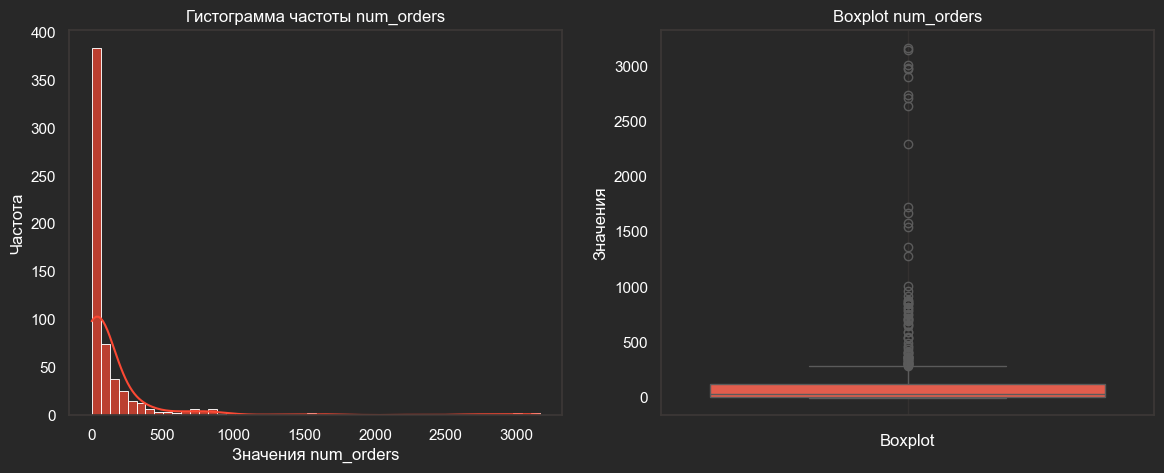

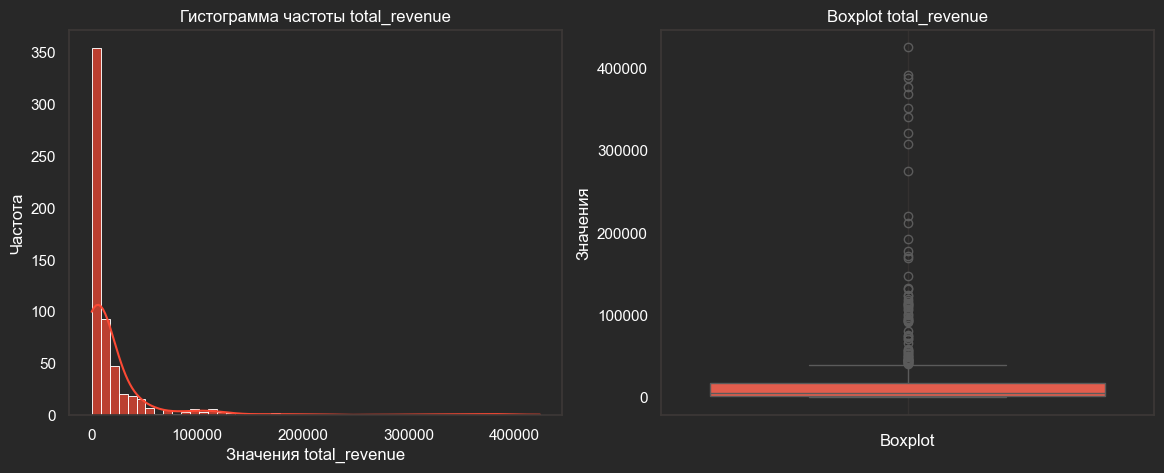

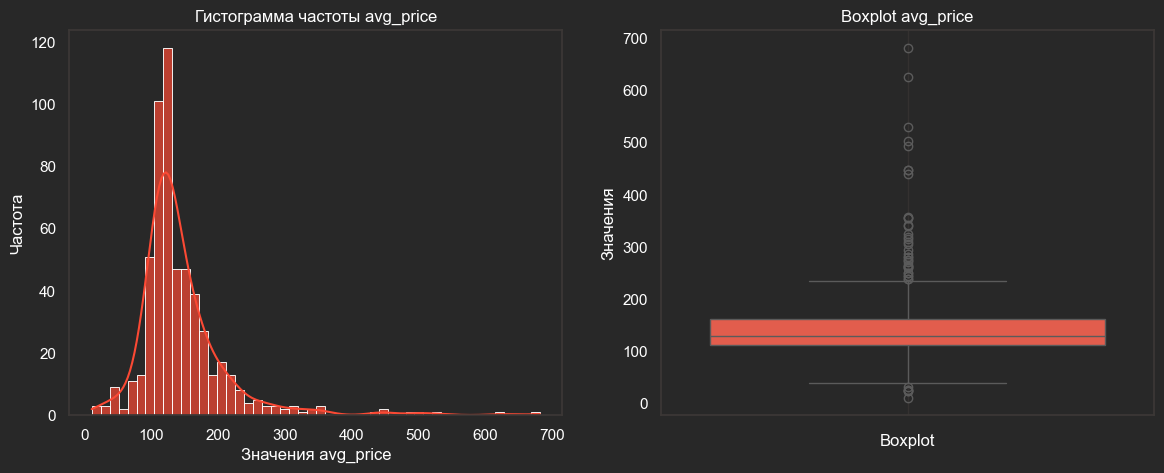

In [75]:
num_plot(monthly, ['num_orders', 'total_revenue', 'avg_price'], figsize=(14, 5))

In [76]:
for col in ['num_orders', 'total_revenue', 'avg_price']:
    print(col, 'describe')
    display(monthly[col].describe())
    print("")

num_orders describe


count     601.000000
mean      160.490849
std       417.167457
min         0.000000
25%         9.000000
50%        32.000000
75%       119.000000
max      3164.000000
Name: num_orders, dtype: float64


total_revenue describe


count       601.000000
mean      21994.009151
std       52807.750685
min           0.000000
25%        1446.260000
50%        5585.560000
75%       17120.190000
max      424628.360000
Name: total_revenue, dtype: float64


avg_price describe


count    556.000000
mean     145.589087
std       68.768899
min       10.900000
25%      111.281356
50%      128.328544
75%      161.864055
max      682.445000
Name: avg_price, dtype: float64

Распределение num_orders сильно правосторонне скошено - основная масса наблюдений сконцентрирована в диапазоне 0-500, медиана 43 при среднем 183. Боксплот показывает многочисленные выбросы от 500 до 3138 - это строки по штату SP в пиковые месяцы.

Распределение аналогично num_orders - выраженный правый скос, медиана 7452 при среднем 25179. Является дубликатом num_orders, но в другом масштабе, стоит удалить.

avg_price менее скошен и близок к нормальному распределению, пик около 120, IQR от 112 до 162. Выбросы есть (до 682) но их мало, ус боксплота доходит до ~ 230. Это подтверждает вывод из ранее проведённого EDA: средний чек стабилен и не имеет выраженного тренда.

In [77]:
adf = adfuller(sp['num_orders'].dropna())
print(f'ADF p-value: {adf[1]:.4f}')
if adf[1] > p_value:
    print("Ряд стационарный, необходимо дифференцирование")
else:
    print("Ряд нестационарный")

ADF p-value: 0.7721
Ряд стационарный, необходимо дифференцирование


In [78]:
sp['num_orders_diff'] = sp['num_orders'].diff(1)
adf_diff = adfuller(sp['num_orders_diff'].dropna())
print(f'ADF p-value: {adf_diff[1]:.4f}')
if adf_diff[1] > p_value:
    print("Ряд стационарный, необходимо повторное дифференцирование diff[2]")
else:
    print("Ряд нестационарный")

ADF p-value: 0.0000
Ряд нестационарный


Убрал стационарность ряда при помощи дифференцирования

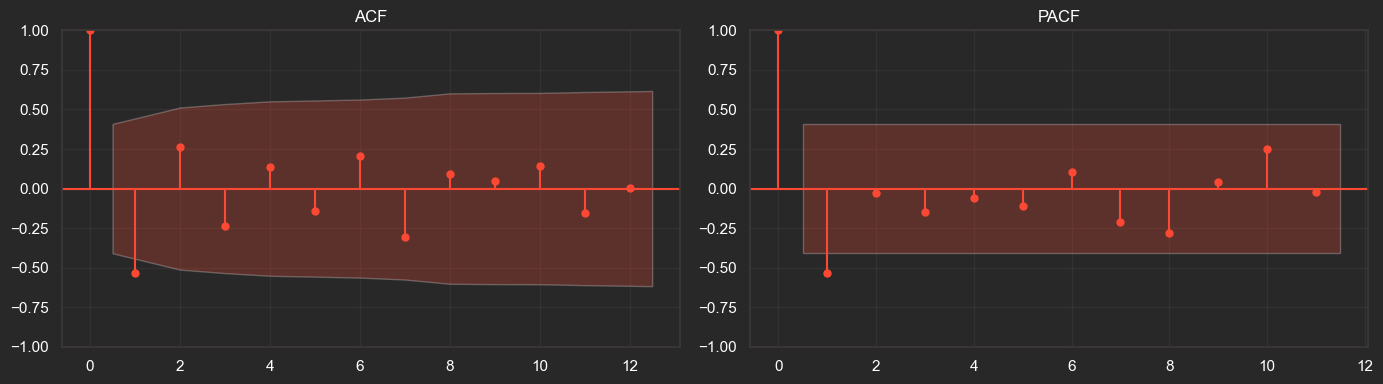

In [79]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(sp['num_orders_diff'].dropna(),  ax=axes[0], lags=12, title='ACF')
plot_pacf(sp['num_orders_diff'].dropna(), ax=axes[1], lags=11, title='PACF')
plt.tight_layout()
plt.show()

По графикам ACF и PACF видно, что статистически значимым является только первый лаг, тогда как более дальние лаги не демонстрируют существенной линейной зависимости с текущими значениями ряда. Поэтому в качестве лаговых признаков целесообразно использовать shift_1 и shift_3. Для описания локального тренда дополнительно используются признаки rolling_3 и rolling_6. Применение более длинных окон (rolling_12) нецелесообразно из-за небольшой длины временного ряда

In [80]:
#Target
monthly['target'] = monthly.groupby('customer_state')['num_orders'].shift(-1)
#Временные фичи
monthly['month'] = monthly['order_purchase_timestamp'].dt.month
monthly['quarter'] = monthly['order_purchase_timestamp'].dt.quarter
monthly['year'] = monthly['order_purchase_timestamp'].dt.year
#Для baseline модели делаем косинусные и синусные фичи
monthly['month_sin'] = np.sin(2 * np.pi * monthly['month'] / 12)
monthly['quarter_sin'] = np.sin(2 * np.pi * monthly['quarter'] / 4)
monthly['month_cos'] = np.cos(2 * np.pi * monthly['month'] / 12)
monthly['quarter_cos'] = np.cos(2 * np.pi * monthly['quarter'] / 4)
#shift/rolling/expanding
monthly['shift_1'] = monthly.groupby('customer_state')['num_orders'].shift(1)
monthly['shift_3'] = monthly.groupby('customer_state')['num_orders'].shift(3)
monthly['rolling_3_mean'] = monthly.groupby('customer_state')['num_orders'].shift(1).rolling(3,min_periods=2).mean()
monthly['rolling_3_std'] = monthly.groupby('customer_state')['num_orders'].shift(1).rolling(3,min_periods=2).std()
monthly['rolling_3_min'] = monthly.groupby('customer_state')['num_orders'].shift(1).rolling(3,min_periods=2).min()
monthly['rolling_3_max'] = monthly.groupby('customer_state')['num_orders'].shift(1).rolling(3,min_periods=2).max()
monthly['rolling_6_mean'] = monthly.groupby('customer_state')['num_orders'].shift(1).rolling(6,min_periods=2).mean()
monthly['rolling_6_std'] = monthly.groupby('customer_state')['num_orders'].shift(1).rolling(6,min_periods=2).std()
monthly['rolling_6_min'] = monthly.groupby('customer_state')['num_orders'].shift(1).rolling(6,min_periods=2).min()
monthly['rolling_6_max'] = monthly.groupby('customer_state')['num_orders'].shift(1).rolling(6,min_periods=2).max()
monthly['expanding_mean'] = monthly.groupby('customer_state')['num_orders'].shift(1).expanding().mean()
monthly['expanding_std'] = monthly.groupby('customer_state')['num_orders'].shift(1).expanding().std()

In [81]:
monthly.head()

,customer_state,order_purchase_timestamp,num_orders,total_revenue,avg_price,total_freight,target,month,quarter,year,...,rolling_3_mean,rolling_3_std,rolling_3_min,rolling_3_max,rolling_6_mean,rolling_6_std,rolling_6_min,rolling_6_max,expanding_mean,expanding_std
0,AC,2017-01-01,2,589.60,147.400000,133.54,3.0,1,1,2017,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,AC,2017-02-01,3,450.40,75.066667,147.00,2.0,2,1,2017,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.000000,NaN
2,AC,2017-03-01,2,455.99,227.995000,74.19,5.0,3,1,2017,...,2.500000,0.707107,2.0,3.0,2.500000,0.707107,2.0,3.0,2.500000,0.707107
3,AC,2017-04-01,5,1162.38,232.476000,189.13,8.0,4,2,2017,...,2.333333,0.577350,2.0,3.0,2.333333,0.577350,2.0,3.0,2.333333,0.577350
4,AC,2017-05-01,8,2094.39,261.798750,277.34,4.0,5,2,2017,...,3.333333,1.527525,2.0,5.0,3.000000,1.414214,2.0,5.0,3.000000,1.414214


In [82]:
monthly.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 601 entries, 0 to 600
Data columns (total 26 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   customer_state            601 non-null    object        
 1   order_purchase_timestamp  601 non-null    datetime64[ns]
 2   num_orders                601 non-null    int64         
 3   total_revenue             601 non-null    float64       
 4   avg_price                 556 non-null    float64       
 5   total_freight             601 non-null    float64       
 6   target                    574 non-null    float64       
 7   month                     601 non-null    int32         
 8   quarter                   601 non-null    int32         
 9   year                      601 non-null    int32         
 10  month_sin                 601 non-null    float64       
 11  quarter_sin               601 non-null    float64       
 12  month_cos             

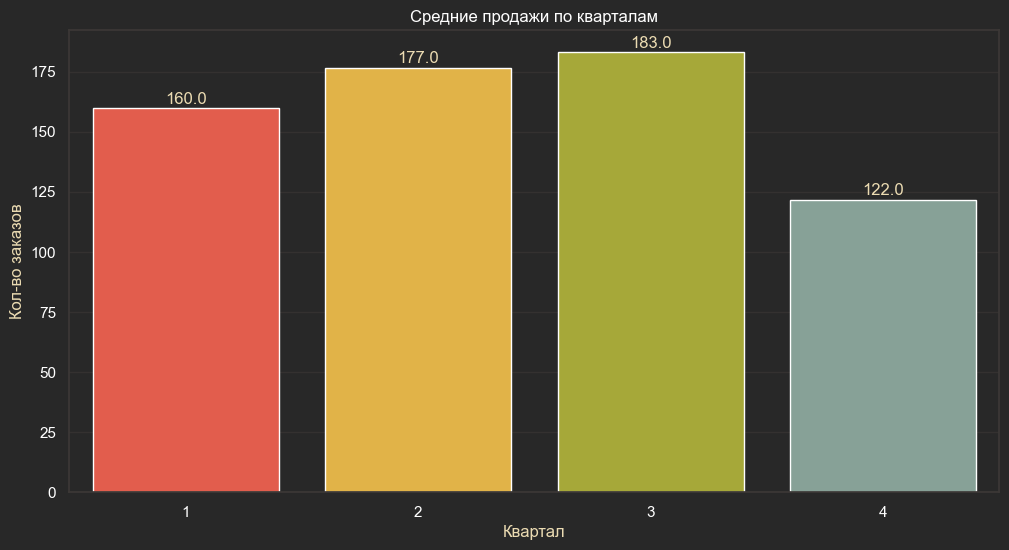

In [83]:
quarter_sales = monthly.groupby('quarter')['num_orders'].mean().reset_index()
plt.figure(figsize=(12, 6))
sns.barplot(data=quarter_sales, x='quarter', y='num_orders', palette=colorbox)
for i, v in enumerate(monthly.groupby('quarter')['num_orders'].mean().round().values):
    plt.text(i, v + 0.5, str(v), ha='center', va='bottom', fontsize=12)
plt.title('Средние продажи по кварталам')
plt.xlabel('Квартал')
plt.ylabel('Кол-во заказов')
plt.show()

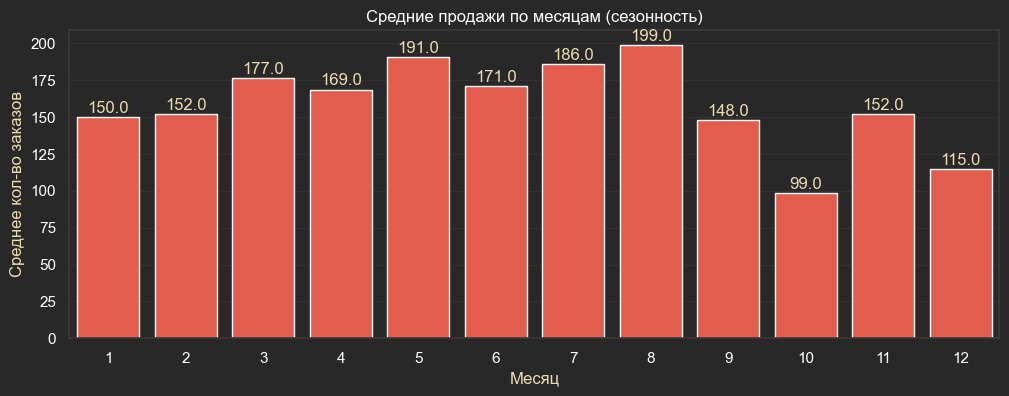

In [84]:
season = monthly.groupby('month')['num_orders'].mean().reset_index()
plt.figure(figsize=(12, 4))
sns.barplot(data=season, x='month', y='num_orders', color=colorbox[0])
for i, v in enumerate(monthly.groupby('month')['num_orders'].mean().round().values):
    plt.text(i, v + 0.5, str(v), ha='center', va='bottom', fontsize=12)
plt.title('Средние продажи по месяцам (сезонность)')
plt.xlabel('Месяц')
plt.ylabel('Среднее кол-во заказов')
plt.show()

Наибольшее количество заказов приходится на Июль ~ 190 заказов в среднем, реже всего покупки совершаются в октябре и декабре. Лето и весна являются наиболее стабильными (от 150 до 190 заказов в среднем в месяц)

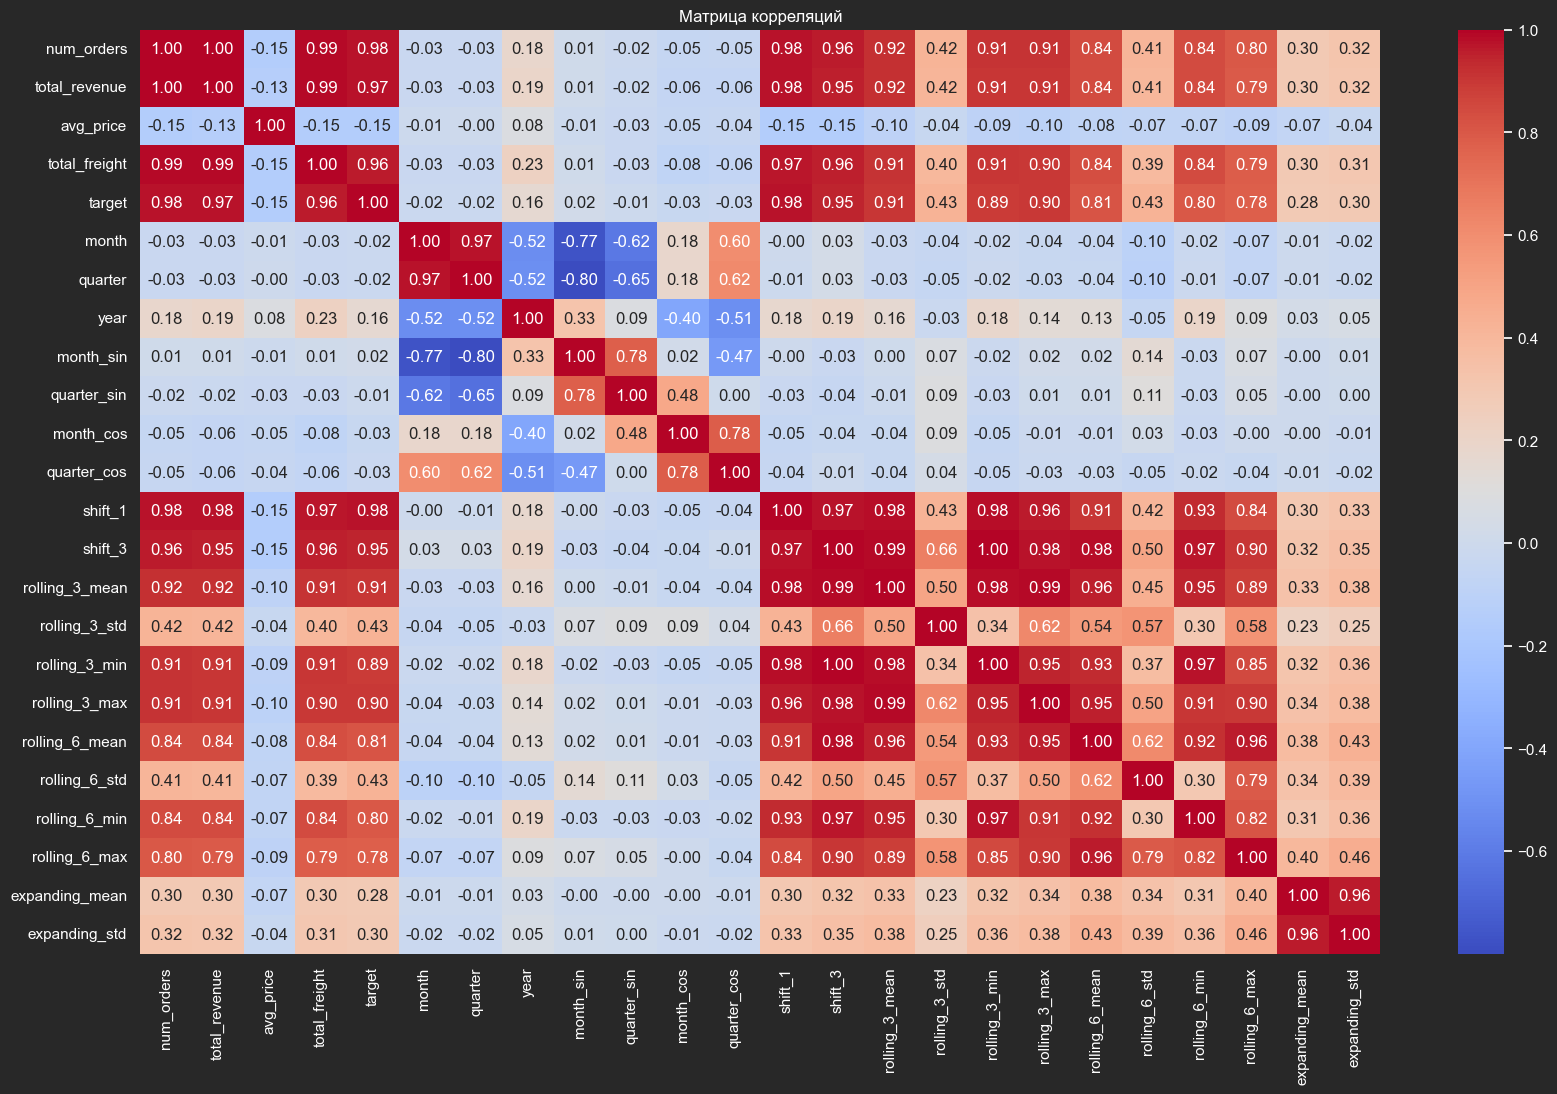

In [85]:
plt.figure(figsize=(20, 12))
sns.heatmap(
    monthly.drop(['order_purchase_timestamp','customer_state'],axis=1).corr(),
    annot=True, fmt='.2f',
    cmap='coolwarm'
)
plt.title('Матрица корреляций', color='white')
plt.grid()
plt.show()

* **num_orders**, **total_revenue**, **total_freight** коррелируют между собой на уровне 0.99-1.00 - это фактически один признак. Для линейных моделей это критическая мультиколлинеарность, оставляем только num_orders, остальные дропаем.

* **target** коррелирует с **shift_1** (0.98) и **shift_3** (0.96), а также имеет сильную корреляцию со скользящими окнами(~ 0.8). Исторические фичи являются сильнейшими предикторами.

* Временные признаки (**month**, **quarter**) слабо коррелируют с target (-0.02 до 0.16) - сезонность в данных слабая, но деревья могут уловить нелинейный паттерн.

* **expanding_mean** и **expanding_std** (0.30-0.32 с **target**) - умеренная связь с целевой переменной

#### Предобработка данных

In [86]:
monthly.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 601 entries, 0 to 600
Data columns (total 26 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   customer_state            601 non-null    object        
 1   order_purchase_timestamp  601 non-null    datetime64[ns]
 2   num_orders                601 non-null    int64         
 3   total_revenue             601 non-null    float64       
 4   avg_price                 556 non-null    float64       
 5   total_freight             601 non-null    float64       
 6   target                    574 non-null    float64       
 7   month                     601 non-null    int32         
 8   quarter                   601 non-null    int32         
 9   year                      601 non-null    int32         
 10  month_sin                 601 non-null    float64       
 11  quarter_sin               601 non-null    float64       
 12  month_cos             

In [87]:
monthly = monthly.dropna()

Данные содержат пропуски, их необходимо удалить.

In [88]:
start_end = monthly.groupby('customer_state')['order_purchase_timestamp'].agg(['min','max'])
start_end

,min,max
customer_state,,
AC,2017-04-01,2018-07-01
AL,2017-01-01,2018-07-01
AM,2017-05-01,2018-07-01
AP,2017-05-01,2018-07-01
BA,2017-01-01,2018-07-01
CE,2017-01-01,2018-07-01
DF,2017-01-01,2018-07-01
ES,2017-01-01,2018-07-01
GO,2017-01-01,2018-07-01


In [89]:
monthly.groupby('customer_state').size().describe()

count    27.000000
mean     18.111111
std       1.552500
min      15.000000
25%      17.500000
50%      19.000000
75%      19.000000
max      19.000000
dtype: float64

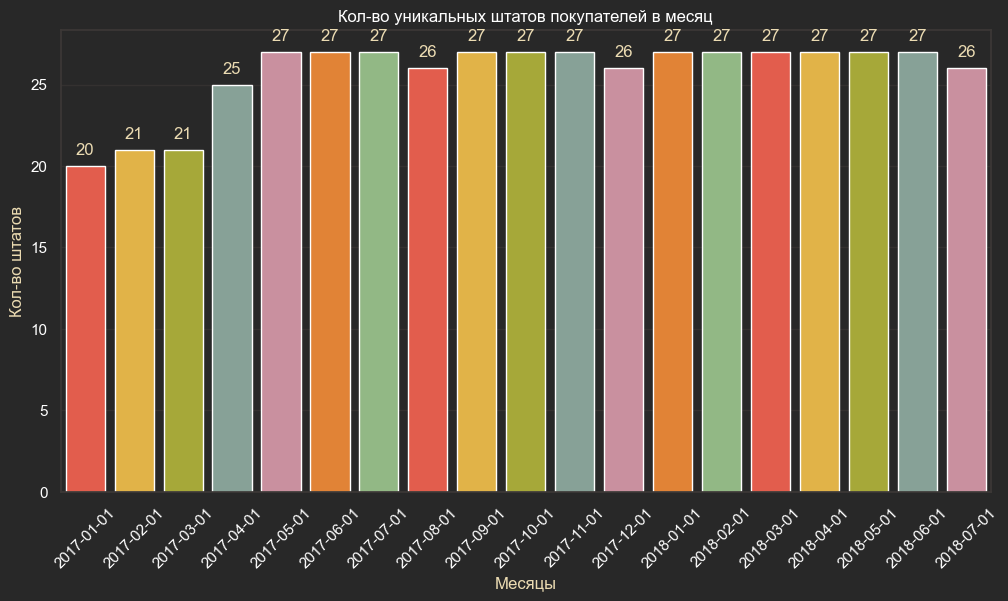

In [90]:
purchase_ts_count = monthly['order_purchase_timestamp'].value_counts().sort_index()
plt.figure(figsize=(12, 6))
sns.barplot(data=purchase_ts_count,palette=colorbox)
for i, v in enumerate(monthly['order_purchase_timestamp'].value_counts().sort_index().values):
    plt.text(i, v + 0.5, str(v), ha='center', va='bottom', fontsize=12)
plt.title('Кол-во уникальных штатов покупателей в месяц')
plt.xlabel('Месяцы')
plt.ylabel('Кол-во штатов')
plt.xticks(rotation=45)
plt.show()

С апреля 2017 по июль 2018 почти каждый месяц содержит данные по 27 штатам - датасет сбалансирован по штатам в этом периоде. Первые три месяца 2017 года содержат 20-21 штат часть малых штатов ещё не имела заказов. Среднее количество месяцев на штат: 18.1 из максимальных 19 (пропуски минимальные).

In [91]:
# Тренировочные
train = monthly[
    monthly['order_purchase_timestamp'] < '2018-02-01'
]
X_train = train.drop(['order_purchase_timestamp','customer_state', 'target'],axis=1)
y_train = train['target']
# Валидация
val = monthly[
    (monthly['order_purchase_timestamp'] >= '2018-02-01')
    &
    (monthly['order_purchase_timestamp'] <= '2018-04-01')
]
X_val = val.drop(['order_purchase_timestamp','customer_state', 'target'],axis=1)
y_val = val['target']
# Тест
test = monthly[
    monthly['order_purchase_timestamp'] > '2018-04-01'
]
X_test = test.drop(['order_purchase_timestamp','customer_state', 'target'],axis=1)
y_test = test['target']

In [92]:
X_test.dtypes

num_orders          int64
total_revenue     float64
avg_price         float64
total_freight     float64
month               int32
quarter             int32
year                int32
month_sin         float64
quarter_sin       float64
month_cos         float64
quarter_cos       float64
shift_1           float64
shift_3           float64
rolling_3_mean    float64
rolling_3_std     float64
rolling_3_min     float64
rolling_3_max     float64
rolling_6_mean    float64
rolling_6_std     float64
rolling_6_min     float64
rolling_6_max     float64
expanding_mean    float64
expanding_std     float64
dtype: object

In [93]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

Проскейлил признаки

#### Baseline LinearRegression (L1,L2,ElNet)

In [127]:
def objective_ridge(trial):
    alpha = trial.suggest_float('alpha', 0.01, 100, log=True)
    model = Ridge(alpha=alpha)
    model.fit(X_train, y_train)
    score = smape(y_val, model.predict(X_val))
    return score

def objective_lasso(trial):
    alpha = trial.suggest_float('alpha', 0.001, 10, log=True)
    model = Lasso(alpha=alpha, max_iter=10000)
    model.fit(X_train, y_train)
    score = smape(y_val, model.predict(X_val))
    return score

def objective_elasticnet(trial):
    alpha    = trial.suggest_float('alpha', 0.001, 10, log=True)
    l1_ratio = trial.suggest_float('l1_ratio', 0.0, 1.0)
    model = ElasticNet(alpha=alpha, l1_ratio=l1_ratio, max_iter=10000)
    model.fit(X_train, y_train)
    score = smape(y_val, model.predict(X_val))
    return score


study_ridge = optuna.create_study(direction='minimize')
study_ridge.optimize(objective_ridge, n_trials=30, show_progress_bar=True)
print('Ridge лучший SMAPE:', study_ridge.best_value)
print('Ridge alpha:', study_ridge.best_params)

study_lasso = optuna.create_study(direction='minimize')
study_lasso.optimize(objective_lasso, n_trials=30, show_progress_bar=True)
print('Lasso лучший SMAPE:', study_lasso.best_value)
print('Lasso alpha:', study_lasso.best_params)

study_en = optuna.create_study(direction='minimize')
study_en.optimize(objective_elasticnet, n_trials=30, show_progress_bar=True)
print('ElasticNet лучший SMAPE:', study_en.best_value)
print('ElasticNet параметры:', study_en.best_params)

  0%|          | 0/30 [00:00<?, ?it/s]

Ridge лучший SMAPE: 0.7748986626053328
Ridge alpha: {'alpha': 97.9422043817592}


  0%|          | 0/30 [00:00<?, ?it/s]

Lasso лучший SMAPE: 0.35867105842134084
Lasso alpha: {'alpha': 5.662793031587538}


  0%|          | 0/30 [00:00<?, ?it/s]

ElasticNet лучший SMAPE: 0.4066263336781142
ElasticNet параметры: {'alpha': 1.526044853040792, 'l1_ratio': 0.37921997595799173}


In [128]:
print("Метрики Ridge на валидационных данных:")
best_ridge = Ridge(
    **study_ridge.best_params,
    random_state=RANDOM_STATE
)
best_ridge.fit(X_train,y_train)
y_pred_ridge = best_ridge.predict(X_val)
mse_ridge = mean_squared_error(y_pred_ridge, y_val)
rmse_ridge = mean_squared_error(y_pred_ridge, y_val,squared=False)
smape_ridge = smape(y_pred_ridge, y_val)
print('MSE:',mse_ridge)
print('RMSE:',rmse_ridge)
print('SMAPE:',smape_ridge)
print('\n')
print("Метрики Lasso на валидационных данных:")
best_lasso = Lasso(
    **study_lasso.best_params,
    random_state=RANDOM_STATE

)
best_lasso.fit(X_train,y_train)
y_pred_lasso = best_lasso.predict(X_val)
mse_lasso = mean_squared_error(y_pred_lasso, y_val)
rmse_lasso = mean_squared_error(y_pred_lasso, y_val,squared=False)
smape_lasso = smape(y_pred_lasso, y_val)
print('MSE:',mse_lasso)
print('RMSE:',rmse_lasso)
print('SMAPE:',smape_lasso)
print('\n')
print("Метрики ElasticNet на валидационных данных:")
best_en = ElasticNet(
    **study_en.best_params,
    random_state=RANDOM_STATE
)
best_en.fit(X_train,y_train)
y_pred_en = best_en.predict(X_val)
mse_en = mean_squared_error(y_pred_en, y_val)
rmse_en = mean_squared_error(y_pred_en, y_val,squared=False)
smape_en = smape(y_pred_en, y_val)
print('MSE:',mse_en)
print('RMSE:',rmse_en)
print('SMAPE:',smape_en)

Метрики Ridge на валидационных данных:
MSE: 5461.108499955056
RMSE: 73.89931325766875
SMAPE: 0.7748986626053328


Метрики Lasso на валидационных данных:
MSE: 6164.619503764763
RMSE: 78.51509093011842
SMAPE: 0.35867105842134084


Метрики ElasticNet на валидационных данных:
MSE: 3356.3278472756638
RMSE: 57.93382299896722
SMAPE: 0.4066263336781142


In [129]:
# RIDGE LOG
with mlflow.start_run(run_name='Ridge'):
    mlflow.log_params(study_ridge.best_params)

    mlflow.log_metrics({
        'MSE': mse_ridge,
        'RMSE': rmse_ridge,
        'SMAPE': smape_ridge
    })

    mlflow.sklearn.log_model(best_ridge, "model")
# LASSO LOG
with mlflow.start_run(run_name='Lasso'):
    mlflow.log_params(study_lasso.best_params)

    mlflow.log_metrics({
        'MSE': mse_lasso,
        'RMSE': rmse_lasso,
        'SMAPE': smape_lasso
    })

    mlflow.sklearn.log_model(best_lasso, "model")
# ELASTICNET LOG
with mlflow.start_run(run_name='ElasticNet'):
    mlflow.log_params(study_en.best_params)

    mlflow.log_metrics({
        'MSE': mse_en,
        'RMSE': rmse_en,
        'SMAPE': smape_en
    })

    mlflow.sklearn.log_model(best_en, "model")

2026/08/31 18:18:33 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/08/31 18:18:37 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/08/31 18:18:42 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


#### Catboost model

In [130]:
def objective_cat(trial):
    params = {
        'iterations' : trial.suggest_int('iterations', 300, 2000),
        'depth' : trial.suggest_int('depth', 3, 8),
        'learning_rate' : trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'l2_leaf_reg' : trial.suggest_float('l2_leaf_reg', 1, 10),
        'bagging_temperature' : trial.suggest_float('bagging_temperature', 0, 1),
        'random_strength' : trial.suggest_float('random_strength', 1, 10),
        'min_data_in_leaf' : trial.suggest_int('min_data_in_leaf', 5, 50),
    }
    model = CatBoostRegressor(**params, random_state=RANDOM_STATE, verbose=0)
    model.fit(X_train, y_train)
    score = smape(y_val, model.predict(X_val))
    return score

study_cat = optuna.create_study(direction='minimize')
study_cat.optimize(objective_cat, n_trials=50, show_progress_bar=True)
print('CatBoost лучший SMAPE:', study_cat.best_value)
print('CatBoost лучшие параметры:', study_cat.best_params)

  0%|          | 0/50 [00:00<?, ?it/s]

CatBoost лучший SMAPE: 0.33661867418446484
CatBoost лучшие параметры: {'iterations': 376, 'depth': 4, 'learning_rate': 0.07388116526429156, 'l2_leaf_reg': 1.6270580323998256, 'bagging_temperature': 0.6619186339401176, 'random_strength': 2.5678739288106742, 'min_data_in_leaf': 50}


In [131]:
print("Метрики CatBoost на валидационных данных:")
best_cat = CatBoostRegressor(
    **study_cat.best_params,
    random_state=RANDOM_STATE,
    verbose=0
)
best_cat.fit(X_train,y_train)
y_pred_cat = best_cat.predict(X_val)
mse_cat = mean_squared_error(y_pred_cat, y_val)
rmse_cat = mean_squared_error(y_pred_cat, y_val,squared=False)
smape_cat = smape(y_pred_cat, y_val)
print('MSE:',mse_cat)
print('RMSE:',rmse_cat)
print('SMAPE:',smape_cat)

Метрики CatBoost на валидационных данных:
MSE: 15940.750504347046
RMSE: 126.25668498874444
SMAPE: 0.33661867418446484


In [132]:
# CATBOOST LOG
with mlflow.start_run(run_name='CatBoost'):
    mlflow.log_params(study_cat.best_params)

    mlflow.log_metrics({
        'MSE': mse_cat,
        'RMSE': rmse_cat,
        'SMAPE': smape_cat
    })

    mlflow.catboost.log_model(best_cat, "model")

2026/08/31 18:21:47 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


In [133]:
joblib.dump(best_cat, r'C:\Users\user\Desktop\best_cat.pkl')
print("Сохранено на рабочий стол")

Сохранено на рабочий стол


In [134]:
test.drop(['order_purchase_timestamp','customer_state', 'target'],axis=1).iloc[0].to_dict()

{'num_orders': 2.0,
 'total_revenue': 1364.8899999999999,
 'avg_price': 682.4449999999999,
 'total_freight': 136.53,
 'month': 5.0,
 'quarter': 2.0,
 'year': 2018.0,
 'month_sin': 0.49999999999999994,
 'quarter_sin': 1.2246467991473532e-16,
 'month_cos': -0.8660254037844387,
 'quarter_cos': -1.0,
 'shift_1': 4.0,
 'shift_3': 3.0,
 'rolling_3_mean': 3.0,
 'rolling_3_std': 1.0000000000000004,
 'rolling_3_min': 2.0,
 'rolling_3_max': 4.0,
 'rolling_6_mean': 4.166666666666667,
 'rolling_6_std': 1.4719601443879746,
 'rolling_6_min': 2.0,
 'rolling_6_max': 6.0,
 'expanding_mean': 4.25,
 'expanding_std': 1.61245154965971}

#### LightGBM

In [135]:
def objective_lgb(trial):
    params = {
        'n_estimators' : trial.suggest_int('n_estimators', 300, 2000),
        'max_depth' : trial.suggest_int('max_depth', 3, 8),
        'learning_rate' : trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'num_leaves' : trial.suggest_int('num_leaves', 8, 64),
        'min_child_samples' : trial.suggest_int('min_child_samples', 10, 50),
        'subsample' : trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree' : trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'reg_alpha' : trial.suggest_float('reg_alpha', 0, 5),
        'reg_lambda' : trial.suggest_float('reg_lambda', 0, 5),
    }
    model = LGBMRegressor(**params, random_state=RANDOM_STATE, verbose=-1)
    model.fit(X_train, y_train)
    score = smape(y_val, model.predict(X_val))
    return score

study_lgb = optuna.create_study(direction='minimize')
study_lgb.optimize(objective_lgb, n_trials=50, show_progress_bar=True)
print('LightGBM лучший SMAPE:', study_lgb.best_value)
print('LightGBM лучшие параметры:', study_lgb.best_params)

  0%|          | 0/50 [00:00<?, ?it/s]

LightGBM лучший SMAPE: 0.2959999937731321
LightGBM лучшие параметры: {'n_estimators': 359, 'max_depth': 4, 'learning_rate': 0.025613760314273894, 'num_leaves': 42, 'min_child_samples': 10, 'subsample': 0.6113086766338438, 'colsample_bytree': 0.8992439601703979, 'reg_alpha': 0.8482226017920053, 'reg_lambda': 3.9897696812455323}


In [136]:
print("Метрики LGBM на валидационных данных:")
best_lgb = LGBMRegressor(
    **study_lgb.best_params,
    random_state=RANDOM_STATE,
    verbose=-1
)
best_lgb.fit(X_train,y_train)
y_pred_lgb = best_lgb.predict(X_val)
mse_lgb = mean_squared_error(y_pred_lgb, y_val)
rmse_lgb = mean_squared_error(y_pred_lgb, y_val,squared=False)
smape_lgb = smape(y_pred_lgb, y_val)
print('MSE:',mse_lgb)
print('RMSE:',rmse_lgb)
print('SMAPE:',smape_lgb)

Метрики LGBM на валидационных данных:
MSE: 27209.09699422056
RMSE: 164.95180203386855
SMAPE: 0.2959999937731321


In [137]:
# LIGHTGBM LOG
with mlflow.start_run(run_name='LightGBM'):
    mlflow.log_params(study_lgb.best_params)

    mlflow.log_metrics({
        'MSE': mse_lgb,
        'RMSE': rmse_lgb,
        'SMAPE': smape_lgb
    })

    mlflow.lightgbm.log_model(best_lgb, "model")

2026/08/31 18:22:05 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


In [138]:
runs = mlflow.search_runs()
runs

,run_id,experiment_id,status,artifact_uri,start_time,end_time,metrics.RMSE,metrics.MSE,metrics.SMAPE,params.reg_alpha,...,params.l2_leaf_reg,params.min_data_in_leaf,params.random_strength,params.bagging_temperature,params.l1_ratio,params.alpha,tags.mlflow.source.type,tags.mlflow.source.name,tags.mlflow.user,tags.mlflow.runName
0,7e191f6312b1456ca2c03dc8fc09aa27,0,FINISHED,file:///C:/Users/user/mlruns/0/7e191f6312b1456...,2026-08-31 14:22:05.678000+00:00,2026-08-31 14:22:10.887000+00:00,164.951802,27209.096994,0.296000,0.8482226017920053,...,None,None,None,None,None,None,NOTEBOOK,Olist_ml_timeseries.ipynb,user,LightGBM
1,5ea0ba6b504c46218cdbc79e052e504f,0,FINISHED,file:///C:/Users/user/mlruns/0/5ea0ba6b504c462...,2026-08-31 14:21:47.063000+00:00,2026-08-31 14:21:50.617000+00:00,126.256685,15940.750504,0.336619,None,...,1.6270580323998256,50,2.5678739288106742,0.6619186339401176,None,None,NOTEBOOK,Olist_ml_timeseries.ipynb,user,CatBoost
2,6a8a81f44b5a48b185e64fb73b3b4223,0,FINISHED,file:///C:/Users/user/mlruns/0/6a8a81f44b5a48b...,2026-08-31 14:18:42.216000+00:00,2026-08-31 14:18:46.849000+00:00,57.933823,3356.327847,0.406626,None,...,None,None,None,None,0.37921997595799173,1.526044853040792,NOTEBOOK,Olist_ml_timeseries.ipynb,user,ElasticNet
3,0bdd9f2f01bc4feca516c37987adb7de,0,FINISHED,file:///C:/Users/user/mlruns/0/0bdd9f2f01bc4fe...,2026-08-31 14:18:37.588000+00:00,2026-08-31 14:18:42.199000+00:00,78.515091,6164.619504,0.358671,None,...,None,None,None,None,None,5.662793031587538,NOTEBOOK,Olist_ml_timeseries.ipynb,user,Lasso
4,c4772f03c70a41f2b8b5605d6b909895,0,FINISHED,file:///C:/Users/user/mlruns/0/c4772f03c70a41f...,2026-08-31 14:18:33.112000+00:00,2026-08-31 14:18:37.569000+00:00,73.899313,5461.108500,0.774899,None,...,None,None,None,None,None,97.9422043817592,NOTEBOOK,Olist_ml_timeseries.ipynb,user,Ridge
5,a9eda7b344074d90ac4bf49432c02d95,0,FINISHED,file:///C:/Users/user/mlruns/0/a9eda7b344074d9...,2026-08-31 14:10:04.474000+00:00,2026-08-31 14:10:09.850000+00:00,198.757221,39504.432985,-2.992822,3.7818858875806995,...,None,None,None,None,None,None,NOTEBOOK,Olist_ml_timeseries.ipynb,user,LightGBM
6,46a132decde0420b84c9818215b66dc2,0,FINISHED,file:///C:/Users/user/mlruns/0/46a132decde0420...,2026-08-31 14:09:38.346000+00:00,2026-08-31 14:09:41.452000+00:00,154.634796,23911.920169,-2.913705,None,...,3.16747160756364,34,5.366765542195172,0.643405277368603,None,None,NOTEBOOK,Olist_ml_timeseries.ipynb,user,CatBoost
7,530c523e7f3c43aaa519385074932bd4,0,FINISHED,file:///C:/Users/user/mlruns/0/530c523e7f3c43a...,2026-08-31 14:07:24.923000+00:00,2026-08-31 14:07:29.491000+00:00,78.944669,6232.260760,326.902844,None,...,None,None,None,None,0.026414170417677574,0.0069311595302040275,NOTEBOOK,Olist_ml_timeseries.ipynb,user,ElasticNet
8,b13699d469a74d41a4a530af55cb61bc,0,FINISHED,file:///C:/Users/user/mlruns/0/b13699d469a74d4...,2026-08-31 14:07:20.350000+00:00,2026-08-31 14:07:24.905000+00:00,73.436900,5392.978341,-11.599877,None,...,None,None,None,None,None,0.0896835236468599,NOTEBOOK,Olist_ml_timeseries.ipynb,user,Lasso
9,69a5cf5618d4401497c3e3d84fc087da,0,FINISHED,file:///C:/Users/user/mlruns/0/69a5cf5618d4401...,2026-08-31 14:07:02.903000+00:00,2026-08-31 14:07:20.330000+00:00,132.368345,17521.378663,-32.781542,None,...,None,None,None,None,None,0.012087611124866908,NOTEBOOK,Olist_ml_timeseries.ipynb,user,Ridge


Логи записываются

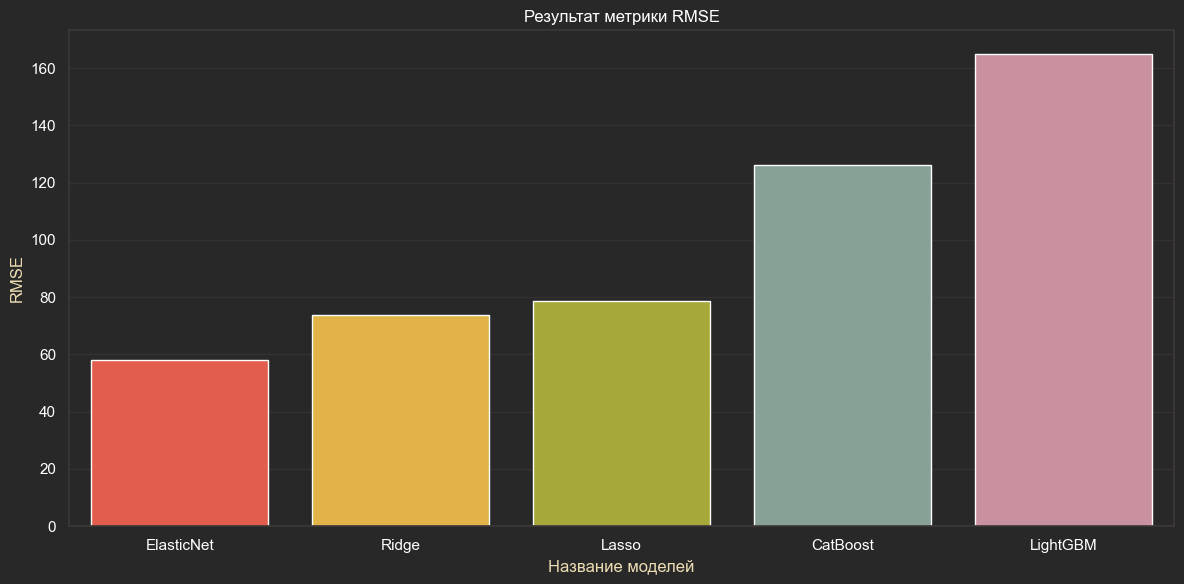

In [139]:
df_metrics = pd.DataFrame({
    'models_name': ['Ridge','Lasso','ElasticNet','CatBoost','LightGBM'],
    'MSE': [mse_ridge, mse_lasso, mse_en, mse_cat, mse_lgb],
    'RMSE': [rmse_ridge, rmse_lasso, rmse_en, rmse_cat, rmse_lgb],
    'SMAPE': [smape_ridge, smape_lasso, smape_en, smape_cat, smape_lgb]
})
plt.figure(figsize=(12,6))
sns.barplot(data = df_metrics.sort_values(by='RMSE'), x='models_name', y='RMSE', palette=colorbox)
plt.title('Результат метрики RMSE')
plt.ylabel('RMSE')
plt.xlabel('Название моделей')
plt.tight_layout()
plt.show()

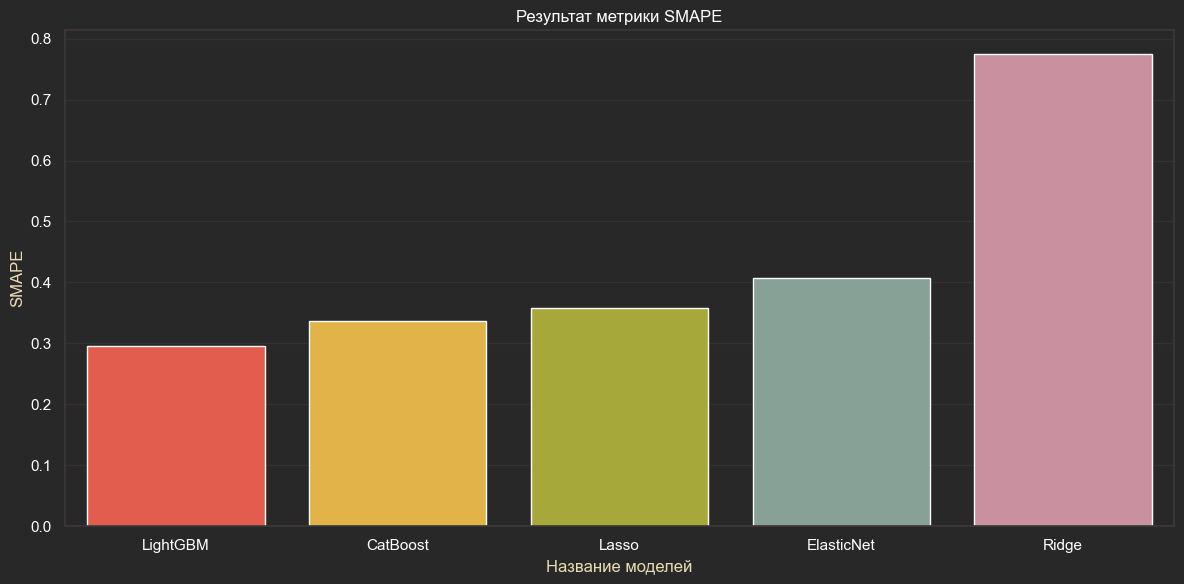

In [140]:
plt.figure(figsize=(12,6))
sns.barplot(data = df_metrics.sort_values(by='SMAPE'), x='models_name', y='SMAPE', palette=colorbox)
plt.title('Результат метрики SMAPE')
plt.ylabel('SMAPE')
plt.xlabel('Название моделей')
plt.tight_layout()
plt.show()

**Общий вывод по моделям:**

Были рассмотрены линейные модели (Ridge, Lasso, ElasticNet) и модели градиентного бустинга (CatBoost, LightGBM). Сравнение проводилось по метрикам MSE, RMSE и SMAPE.

По метрике RMSE лучшие результаты показали линейные модели, особенно ElasticNet (RMSE = 58.36), что говорит о меньшей средней ошибке прогноза количества заказов. Модели градиентного бустинга продемонстрировали существенно более высокий RMSE (около 150).

По метрике SMAPE ситуация обратная: наилучшие результаты показали LightGBM (34.31) и CatBoost (34.55), немного опередив линейные модели. Это означает, что относительно истинных значений их прогнозы оказались несколько точнее.

Таким образом, разные метрики выделяют разных лидеров. ElasticNet обеспечивает наиболее точные прогнозы в абсолютных величинах, тогда как LightGBM и CatBoost показывают меньшую относительную ошибку. Выбор лучшей модели зависит от того, какая метрика является приоритетной для бизнес-задачи.

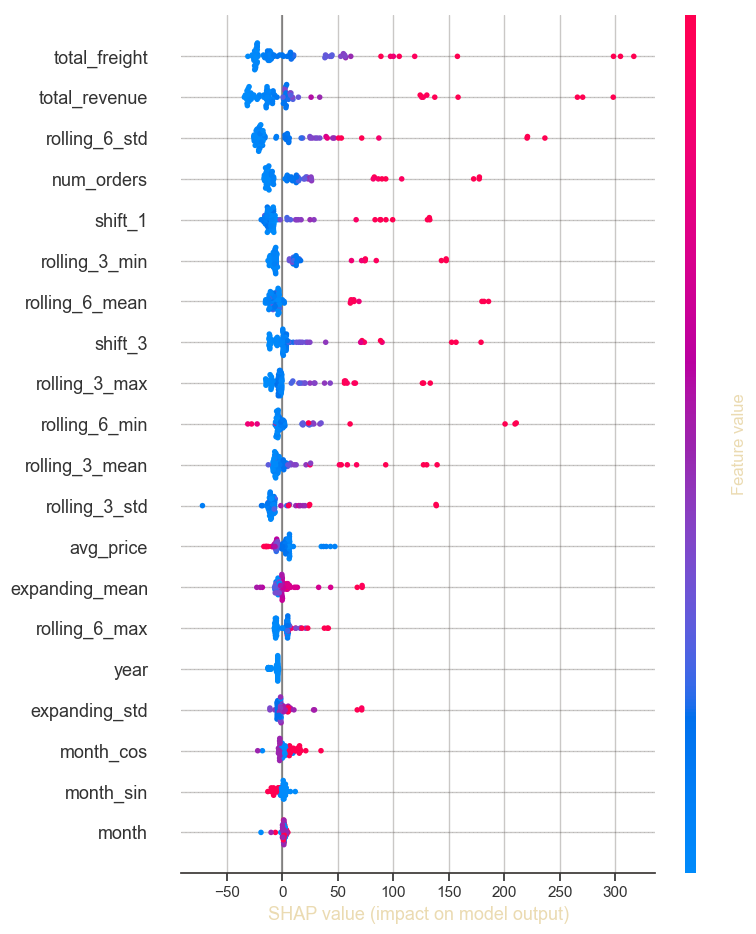

In [141]:
feature_names = [
    'num_orders',
    'total_revenue',
    'avg_price',
    'total_freight',
    'month',
    'quarter',
    'year',
    'month_sin',
    'quarter_sin',
    'month_cos',
    'quarter_cos',
    'shift_1',
    'shift_3',
    'rolling_3_mean',
    'rolling_3_std',
    'rolling_3_min',
    'rolling_3_max',
    'rolling_6_mean',
    'rolling_6_std',
    'rolling_6_min',
    'rolling_6_max',
    'expanding_mean',
    'expanding_std'
]

explainer = shap.TreeExplainer(best_cat)

shap_values = explainer.shap_values(X_val)
with plt.rc_context({'axes.facecolor': 'white', 'figure.facecolor': 'white'}):
    shap.summary_plot(
        shap_values,
        X_val,
        max_display=20,
        feature_names=feature_names
    )

### Топ-3 наиболее значимых:

* **total_revenue**
  
* **num_orders**
  
* **shift_3**

### Топ-3 наименее значимых:

* **quarter**
  
* **month**
  
* **month_cos**

Вывод: модель в основном опирается на текущие значения продаж и заказы, а также на краткосрочную динамику ряда. Календарные признаки (month, quarter) имеют минимальный вклад.